# Computer Networks (CS3001) — Research Project Phase 3
## Complete Research Implementation and Experimental Evaluation

**Topic:** Optimizing for Latency and Bandwidth in Multiplayer Games via Adaptive State Synchronization (ASS)

**Institution:** FAST-NUCES Islamabad | **Course:** CS3001 Computer Networks  
**Instructors:** Ms. Laraib Afzaal, Mr. Ubaid UrRehman, Mr. Atif Saeed  
**Group:** Afaq Ahsan (24i-6516, AI-C) · Qanitah Ali (24i-3125, AI-A)

---

## 1. Project Introduction

### 1.1 Research Problem

Multiplayer game sessions degrade in quality when network conditions deteriorate. Existing
approaches either (a) predict latency/bandwidth but do not act on that prediction in real time,
or (b) mitigate lag using fixed rules without any predictive component.

### 1.2 Research Gap

> No published system **forecasts** near-term network latency and available bandwidth from
> live multiplayer traffic and uses that forecast to **adaptively resize or re-prioritize the
> state-synchronization payload** sent to each client — validated across more than one game genre
> and more than one real network path.

Three sub-gaps from the Phase 1–2 literature review:
- **Gap 1:** Prediction–action loop validated only in narrow single-context settings (Monaco et al., CLAAP)
- **Gap 2:** No unified dataset spanning latency, jitter, loss, and adaptive-sync signals
- **Gap 3:** Latency-reduction layers evaluated in isolation, never combined

### 1.3 Research Objectives

1. Implement a **lightweight drift-aware condition predictor** (RBF Network + drift detection)  
2. Implement the **ASS Controller** mapping predicted severity → three synchronization levers  
3. Benchmark against **four baselines** across four network paths and two genres  
4. Conduct **ablation studies** and **session-level statistical significance testing**

### 1.4 Phase 3 Scope

This notebook is the primary research deliverable. It:
- Loads the corrected synthetic dataset
- Performs session-based train/validation/test splitting
- Trains a genuine RBF Network predictor (K-means centres + least-squares weights)
- Runs all 8 methods (4 baselines + proposed + 3 ablations) vectorised on the test set
- Generates all final research figures in executable code cells
- Performs session-level statistical analysis

> **⚠️ SYNTHETIC DATASET NOTICE:** The dataset used throughout this notebook is entirely
> synthetic. It was generated by a parameterized stochastic simulation (AR(1) processes,
> burst loss model) calibrated to approximate realistic multiplayer network conditions.
> It is NOT collected real-world multiplayer traffic. All results reflect simulation outputs.


---
## 2. Phase 2 Methodology and Implementation Changes

### 2.1 Phase 2 Proposed Architecture (Steps 5–6)

| Component | Phase 2 Design | Phase 3 Implementation |
|-----------|---------------|------------------------|
| Predictor | RBF Network + BOCPD | RBF Network (K-means centres, least-squares weights) + CUSUM drift monitor |
| BOCPD | Full Bayesian posterior over changepoints | Sliding-window error threshold (documented approximation) |
| Controller | Monotonic threshold policy | Implemented exactly as specified |
| Baselines | A: Static, B: ALC, C: CLAAP-gate, D: Static placement | Implemented as documented approximations |
| Dataset | Real-world multi-path multi-genre | Fully synthetic (documented) |

### 2.2 Methodology Changes and Justifications

The full list with justifications is in `METHODOLOGY_CHANGES.md`. Summary:

1. **BOCPD approximated** — full Bayesian Online Changepoint Detection (Adams & MacKay, 2007) is replaced by a
   sliding-window error z-score monitor. Online retraining after a detection is **not** implemented.
2. **Synthetic dataset** — no public dataset combines latency, jitter, loss, bandwidth and game-state signals
   across genres and paths, so data is generated by a parameterised stochastic simulation.
3. **Threshold severity labels** — per-tick thresholds on RTT and window loss replace majority-vote labelling.
4. **Future prediction targets** — the predictor is trained on targets 5 ticks ahead (≈83 ms); these columns are
   never used as inputs.
5. **Session-based splitting** — whole sessions go to train/validation/test (GroupShuffleSplit) to avoid leakage.
6. **Traffic estimated, not capacity-subtracted** — sync traffic is computed from payload, compression, update
   rate, clients and tick rate; reduction is reported relative to Baseline A.
7. **Gameplay metrics are proxies** — FPS / reconciliation / fairness need a game engine; only a clearly
   labelled *simulated* sync-quality proxy is reported.
8. **Predictor is genuinely trained** — an early prototype script used a placeholder predictor that perturbed
   the ground-truth label; it has been removed from the codebase.
9. **Extra evaluation added** — naive forecasting baselines (persistence) and predictor-source ablations
   (`ASS_Reactive`, `ASS_Oracle`).


---
## 3. Experimental Environment


In [1]:
import sys, os, platform, time
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
rng  = np.random.default_rng(SEED)

# ── Plot style ────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi':        120,
    'font.family':       'DejaVu Sans',
    'axes.titlesize':    12,
    'axes.labelsize':    10,
    'legend.fontsize':   9,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
})
sns.set_theme(style='whitegrid', palette='colorblind')
os.makedirs('results/figures', exist_ok=True)
os.makedirs('results/tables',  exist_ok=True)
os.makedirs('results/logs',    exist_ok=True)

print(f"Python:     {sys.version.split()[0]}")
print(f"NumPy:      {np.__version__}")
print(f"Pandas:     {pd.__version__}")
print(f"SciPy:      {scipy.__version__}")
print(f"Scikit:     {sklearn.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"OS:         {platform.system()} {platform.release()}")
print()
print("Simulation parameters:")
print("  Tick rate:     60 Hz")
print("  Ticks/session: 600 (10 s simulated); 575 valid rows after warm-up + horizon")
print("  Horizon H:     5 ticks ≈ 83 ms")
print("  Paths:         LAN, Home_Broadband, Mobile_4G, CrossRegion_Cloud")
print("  Genres:        Shooter, Racing")
print("  Client counts: 4, 8, 16, 32")
print("  Repetitions:   30 per cell")
print("  Total sessions: 4×2×4×30 = 960")
print("  Total rows:    960 × 575 = 552,000")
print(f"  Global seed:   {SEED}")


Python:     3.14.3
NumPy:      2.4.4
Pandas:     3.0.2
SciPy:      1.18.1
Scikit:     1.9.1
Matplotlib: 3.11.2
OS:         Windows 11

Simulation parameters:
  Tick rate:     60 Hz
  Ticks/session: 600 (10 s simulated); 575 valid rows after warm-up + horizon
  Horizon H:     5 ticks ≈ 83 ms
  Paths:         LAN, Home_Broadband, Mobile_4G, CrossRegion_Cloud
  Genres:        Shooter, Racing
  Client counts: 4, 8, 16, 32
  Repetitions:   30 per cell
  Total sessions: 4×2×4×30 = 960
  Total rows:    960 × 575 = 552,000
  Global seed:   42


---
## 4. Dataset Loading and Initial Inspection

> **⚠️ SYNTHETIC DATASET:** The dataset below was generated by `generate_dataset.py` using
> parameterized stochastic simulation. It is NOT real-world multiplayer traffic.


In [2]:
# Load the synthetic dataset
DATASET_PATH = 'dataset/network_dataset.csv'   # produced by generate_dataset.py

print(f'Loading: {DATASET_PATH}')
df_raw = pd.read_csv(DATASET_PATH)

print(f'\nShape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')

# Column inventory
print('\nColumn inventory:')
for col in df_raw.columns:
    is_future = col.startswith('future_')
    role = 'FUTURE TARGET (never used as input)' if is_future else 'feature/identifier'
    print(f'  {col:<25} {str(df_raw[col].dtype):<12} {role}')

Loading: dataset/network_dataset.csv



Shape: 552,000 rows × 25 columns

Column inventory:
  path                      str          feature/identifier
  genre                     str          feature/identifier
  n_clients                 int64        feature/identifier
  repetition                int64        feature/identifier
  tick                      int64        feature/identifier
  rtt_ms                    float64      feature/identifier
  jitter_ms                 float64      feature/identifier
  loss_rate                 float64      feature/identifier
  bandwidth_mbps            float64      feature/identifier
  entity_count              int64        feature/identifier
  payload_bytes             int64        feature/identifier
  rtt_mean                  float64      feature/identifier
  rtt_std                   float64      feature/identifier
  rtt_min                   float64      feature/identifier
  rtt_max                   float64      feature/identifier
  jitter_mean               float64      featur

In [3]:
# Initial inspection
print('=== Summary statistics — network telemetry ===')
display(df_raw[['rtt_ms','jitter_ms','loss_rate','bandwidth_mbps',
                'entity_count','payload_bytes']].describe().T.round(3))

print('\n=== Missing values ===')
mv = df_raw.isnull().sum()
print(mv[mv > 0] if mv.sum() > 0 else 'None — dataset is complete')

print(f'\n=== Duplicate rows: {df_raw.duplicated().sum()} ===')

print('\n=== Session counts ===')
sessions = df_raw.groupby(['path','genre','n_clients','repetition']).size()
print(f'Total sessions: {len(sessions):,}')
print(f'Ticks/session:  {sessions.min()} to {sessions.max()} (all equal = {(sessions.min()==sessions.max())})')

print('\n=== Distribution by path, genre, severity ===')
for col in ['path','genre','severity']:
    print(f'\n{col}:')
    print(df_raw[col].value_counts().sort_index().to_string())


=== Summary statistics — network telemetry ===


,count,mean,std,min,25%,50%,75%,max
rtt_ms,552000.0,79.839,66.573,1.0,23.15,63.95,126.550,548.26
jitter_ms,552000.0,14.461,21.407,0.0,2.00,8.08,18.910,263.83
loss_rate,552000.0,0.008,0.021,0.0,0.00,0.00,0.000,0.25
bandwidth_mbps,552000.0,48.305,31.802,1.0,22.89,36.70,65.142,148.20
entity_count,552000.0,12.760,6.918,4.0,7.00,11.00,17.000,31.00
payload_bytes,552000.0,374.369,185.457,100.0,233.00,333.00,499.000,799.00



=== Missing values ===


None — dataset is complete



=== Duplicate rows: 0 ===

=== Session counts ===
Total sessions: 960
Ticks/session:  575 to 575 (all equal = True)

=== Distribution by path, genre, severity ===

path:


path
CrossRegion_Cloud    138000
Home_Broadband       138000
LAN                  138000
Mobile_4G            138000

genre:
genre
Racing     276000
Shooter    276000

severity:
severity
0    217486
1     94902
2    122216
3    117396


---
## 5. Exploratory Data Analysis

All plots reflect synthetic simulation data. Labels indicate this throughout.


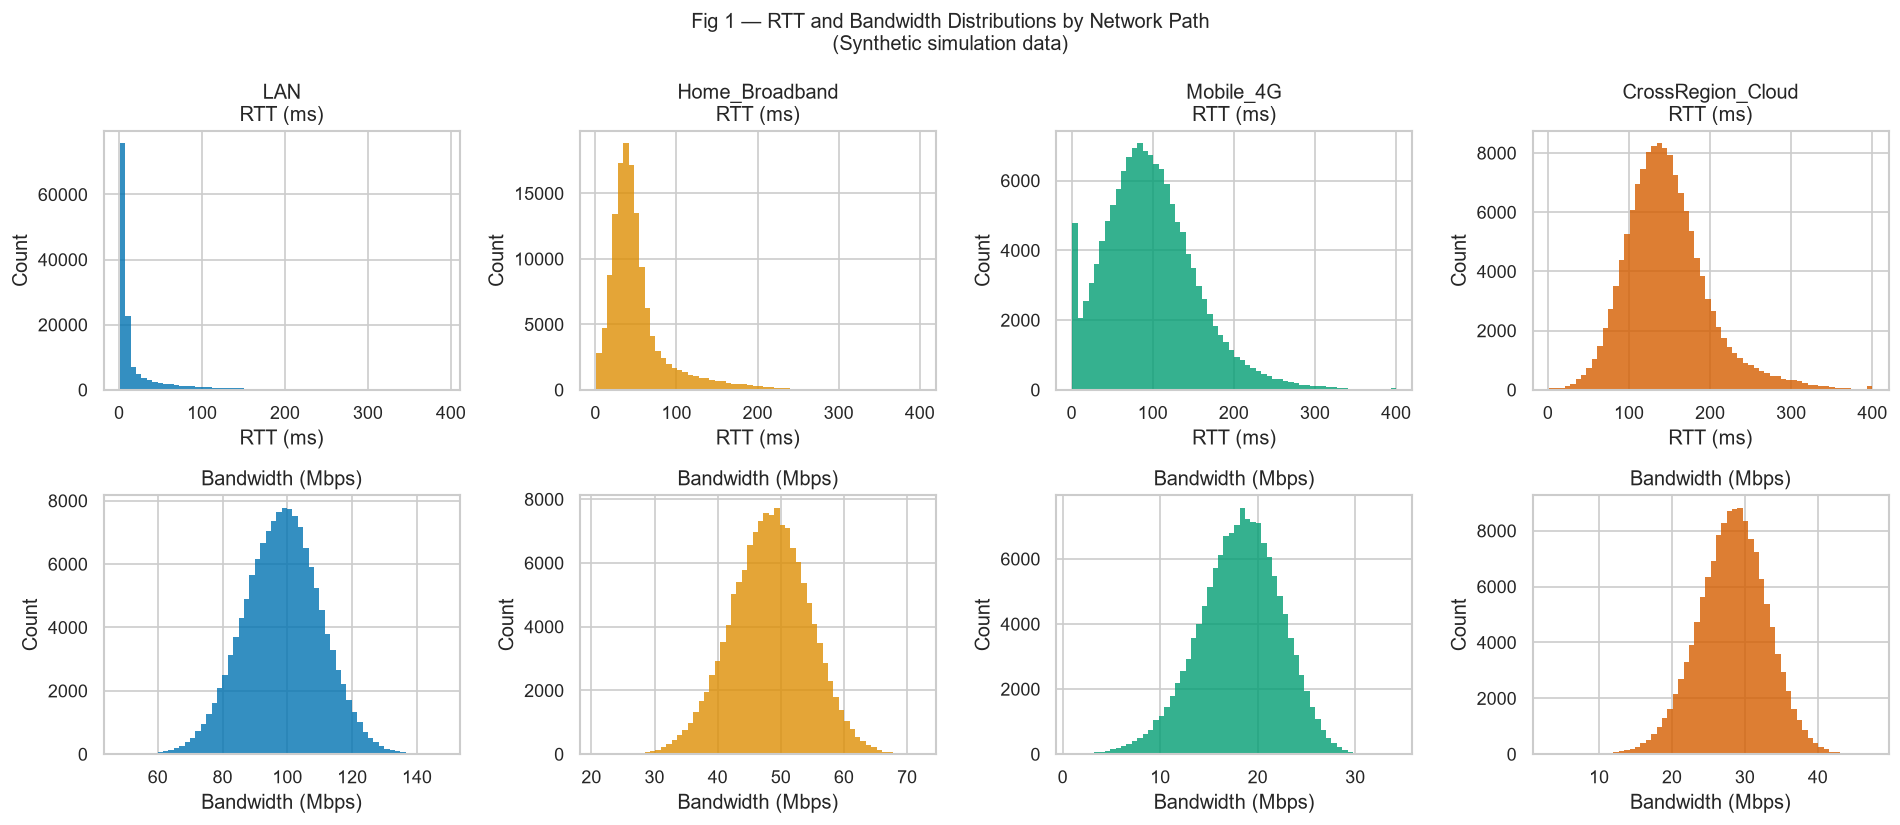

Fig 1 saved.


In [4]:
# Figure: RTT and Bandwidth distributions by network path
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
paths = ['LAN','Home_Broadband','Mobile_4G','CrossRegion_Cloud']
colors = sns.color_palette('colorblind', 4)

for i, (path, col) in enumerate(zip(paths, colors)):
    sub = df_raw[df_raw['path']==path]
    # RTT distribution
    axes[0,i].hist(sub['rtt_ms'].clip(upper=400), bins=60, color=col, alpha=0.8, edgecolor='none')
    axes[0,i].set_title(f'{path}\nRTT (ms)')
    axes[0,i].set_xlabel('RTT (ms)')
    axes[0,i].set_ylabel('Count')
    # Bandwidth distribution
    axes[1,i].hist(sub['bandwidth_mbps'], bins=60, color=col, alpha=0.8, edgecolor='none')
    axes[1,i].set_title(f'Bandwidth (Mbps)')
    axes[1,i].set_xlabel('Bandwidth (Mbps)')
    axes[1,i].set_ylabel('Count')

fig.suptitle('Fig 1 — RTT and Bandwidth Distributions by Network Path\n(Synthetic simulation data)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig01_rtt_bw_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 1 saved.')


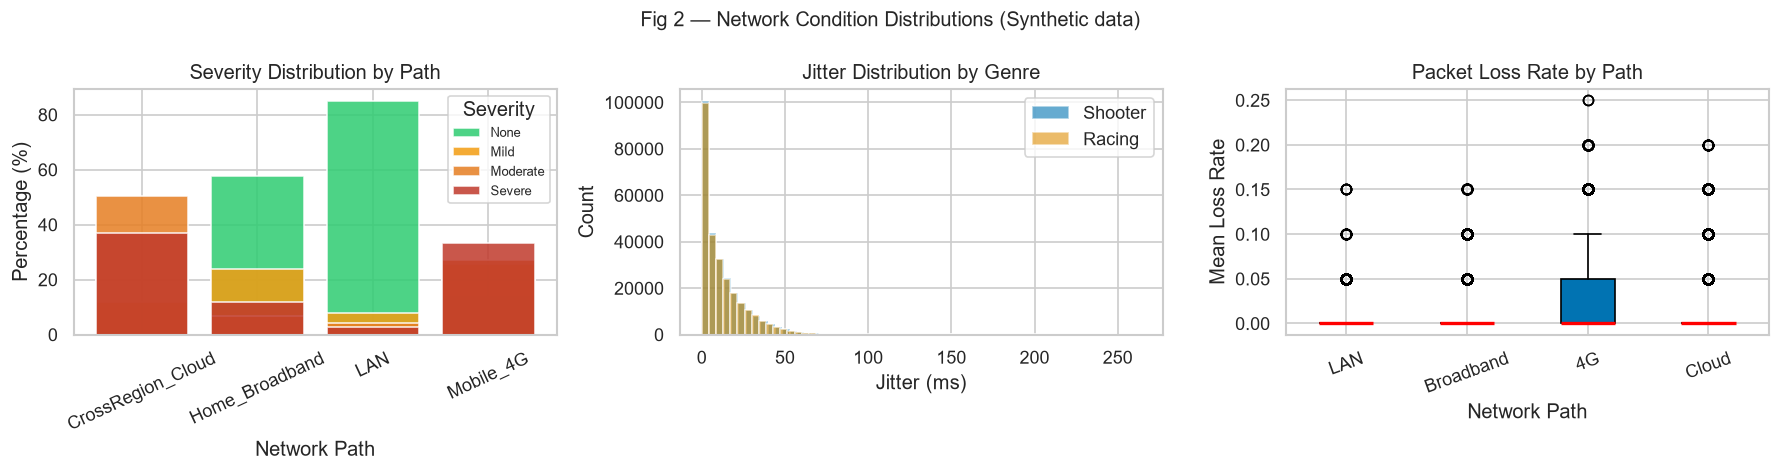

Fig 2 saved.


In [5]:
# Figure: Severity distribution and jitter
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Severity by path
sev_path = df_raw.groupby(['path','severity']).size().reset_index(name='count')
sev_pct  = sev_path.copy()
totals   = sev_pct.groupby('path')['count'].transform('sum')
sev_pct['pct'] = sev_pct['count'] / totals * 100

sev_names = {0:'None',1:'Mild',2:'Moderate',3:'Severe'}
for sev_id, color in zip([0,1,2,3], ['#2ecc71','#f39c12','#e67e22','#c0392b']):
    sub = sev_pct[sev_pct['severity']==sev_id]
    axes[0].bar(sub['path'], sub['pct'], label=sev_names[sev_id],
                color=color, alpha=0.85)
axes[0].set_title('Severity Distribution by Path')
axes[0].set_xlabel('Network Path')
axes[0].set_ylabel('Percentage (%)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title='Severity', fontsize=8)

# Jitter by genre
for genre, style in [('Shooter','-'),('Racing','--')]:
    sub = df_raw[df_raw['genre']==genre]['jitter_ms']
    axes[1].hist(sub, bins=60, alpha=0.6, label=genre)
axes[1].set_title('Jitter Distribution by Genre')
axes[1].set_xlabel('Jitter (ms)')
axes[1].set_ylabel('Count')
axes[1].legend()

# Loss rate across paths (boxplot)
path_order = ['LAN','Home_Broadband','Mobile_4G','CrossRegion_Cloud']
bp_data = [df_raw[df_raw['path']==p]['loss_rate'].values for p in path_order]
axes[2].boxplot(bp_data, tick_labels=['LAN','Broadband','4G','Cloud'], patch_artist=True,
                medianprops=dict(color='red',linewidth=2))
axes[2].set_title('Packet Loss Rate by Path')
axes[2].set_xlabel('Network Path')
axes[2].set_ylabel('Mean Loss Rate')
axes[2].tick_params(axis='x', rotation=20)

fig.suptitle('Fig 2 — Network Condition Distributions (Synthetic data)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig02_severity_jitter_loss.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 2 saved.')


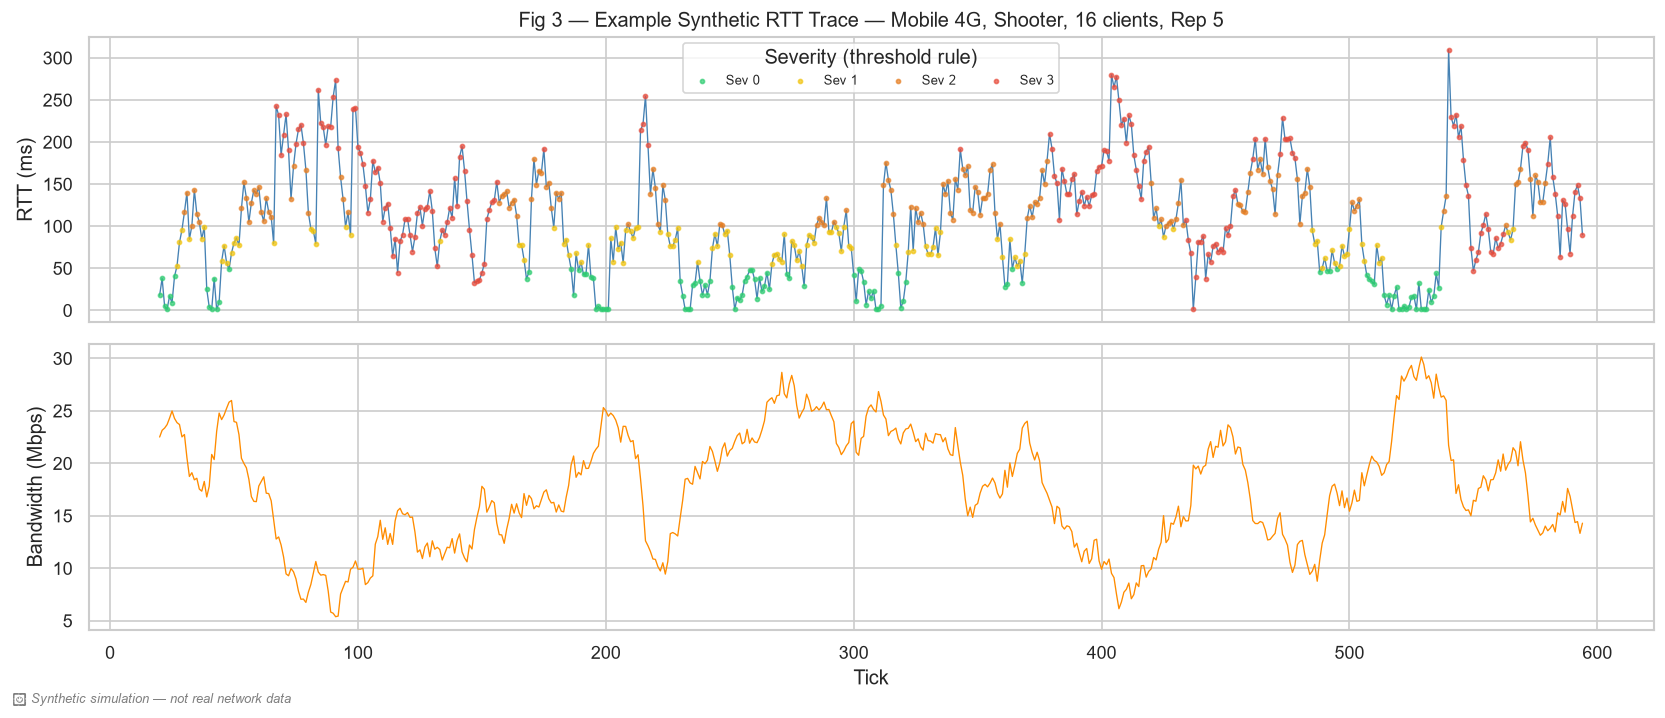

Fig 3 saved.


In [6]:
# Figure: Example RTT trace across one session showing severity classes
sample_sess = df_raw[
    (df_raw['path']=='Mobile_4G') &
    (df_raw['genre']=='Shooter') &
    (df_raw['n_clients']==16) &
    (df_raw['repetition']==5)
].sort_values('tick')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
sev_colors = {0:'#2ecc71', 1:'#f1c40f', 2:'#e67e22', 3:'#e74c3c'}

ax1.plot(sample_sess['tick'], sample_sess['rtt_ms'], linewidth=0.8, color='steelblue')
for sev_id, col in sev_colors.items():
    mask = sample_sess['severity'] == sev_id
    ax1.scatter(sample_sess['tick'][mask], sample_sess['rtt_ms'][mask],
                c=col, s=6, label=f'Sev {sev_id}', alpha=0.7, zorder=3)
ax1.set_ylabel('RTT (ms)')
ax1.set_title('Fig 3 — Example Synthetic RTT Trace — Mobile 4G, Shooter, 16 clients, Rep 5')
ax1.legend(title='Severity (threshold rule)', ncol=4, fontsize=8)

ax2.plot(sample_sess['tick'], sample_sess['bandwidth_mbps'], linewidth=0.8, color='darkorange')
ax2.set_ylabel('Bandwidth (Mbps)')
ax2.set_xlabel('Tick')

fig.text(0.01, 0.01, '⚠ Synthetic simulation — not real network data',
         fontsize=8, color='gray', style='italic')
plt.tight_layout()
plt.savefig('results/figures/fig03_rtt_trace.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 3 saved.')


---
## 6. Preprocessing and Feature Engineering

### 6.1 Feature and Target Definitions

**Predictor input features** (13 columns — all historical, never future):

| Feature | Description |
|---------|-------------|
| rtt_mean, rtt_std, rtt_min, rtt_max | Rolling-window RTT statistics (20-tick window) |
| jitter_mean, jitter_std | Rolling jitter statistics |
| bw_mean, bw_std | Rolling bandwidth statistics |
| loss_rate_mean | Mean packet loss rate over rolling window |
| entity_count | Number of entities in current game state |
| payload_bytes | Base payload size (before compression) |
| genre_encoded | 0=Shooter, 1=Racing |
| n_clients | Concurrent client count |

**Prediction targets** (3 columns — NEVER used as inputs):

| Target | Description | Horizon |
|--------|-------------|---------|
| future_rtt_ms_h5 | RTT at tick t+5 | 5 ticks ≈ 83ms |
| future_bw_mbps_h5 | Bandwidth at tick t+5 | 5 ticks ≈ 83ms |
| future_severity_h5 | Severity class at tick t+5 | 5 ticks ≈ 83ms |

### 6.2 Session-Based Train/Validation/Test Split

Sessions (960 total) are split as complete groups to prevent session leakage:
- **Train:** 70% = 672 sessions × 575 ticks = **386,400 rows**
- **Validation:** 15% = 144 sessions × 575 ticks = **82,800 rows**  
- **Test:** 15% = 144 sessions × 575 ticks = **82,800 rows**

No tick from a session in test ever appears in training.


In [7]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler

FEATURE_COLS = [
    'rtt_mean','rtt_std','rtt_min','rtt_max',
    'jitter_mean','jitter_std',
    'bw_mean','bw_std',
    'loss_rate_mean',
    'entity_count','payload_bytes',
    'genre_encoded','n_clients',
]
TARGET_RTT = 'future_rtt_ms_h5'
TARGET_BW  = 'future_bw_mbps_h5'
TARGET_SEV = 'future_severity_h5'

# LEAKAGE CHECK: verify no future columns in features
forbidden = {TARGET_RTT, TARGET_BW, TARGET_SEV, 'severity'}
leakage   = [c for c in FEATURE_COLS if c in forbidden]
assert len(leakage) == 0, f"LEAKAGE DETECTED: {leakage}"
print(f"Leakage check PASSED — no future columns in {len(FEATURE_COLS)} features")

# Session labels for grouping
df_raw['session_id'] = (
    df_raw['path'] + '__' + df_raw['genre'] + '__' +
    df_raw['n_clients'].astype(str) + '__' + df_raw['repetition'].astype(str)
)
groups = df_raw['session_id'].values

# First split: 70% train | 30% temp
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss1.split(df_raw, groups=groups))
df_temp = df_raw.iloc[temp_idx].copy()
groups_temp = groups[temp_idx]

# Second split: split temp 50/50 → 15% val | 15% test
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_rel_idx, test_rel_idx = next(gss2.split(df_temp, groups=groups_temp))

df_train = df_raw.iloc[train_idx].copy()
df_val   = df_temp.iloc[val_rel_idx].copy()
df_test  = df_temp.iloc[test_rel_idx].copy()

print(f"\nSplit sizes:")
print(f"  Train: {len(df_train):>8,} rows  ({df_train['session_id'].nunique()} sessions)")
print(f"  Val:   {len(df_val):>8,} rows  ({df_val['session_id'].nunique()} sessions)")
print(f"  Test:  {len(df_test):>8,} rows  ({df_test['session_id'].nunique()} sessions)")
print(f"  Total: {len(df_train)+len(df_val)+len(df_test):>8,} rows")

# Verify no session leakage
train_sessions = set(df_train['session_id'])
val_sessions   = set(df_val['session_id'])
test_sessions  = set(df_test['session_id'])
assert len(train_sessions & val_sessions) == 0,  'LEAKAGE: train ∩ val'
assert len(train_sessions & test_sessions) == 0, 'LEAKAGE: train ∩ test'
assert len(val_sessions   & test_sessions) == 0, 'LEAKAGE: val ∩ test'
print("\nSession leakage check PASSED — all three splits are disjoint")


Leakage check PASSED — no future columns in 13 features



Split sizes:
  Train:  386,400 rows  (672 sessions)
  Val:     82,800 rows  (144 sessions)
  Test:    82,800 rows  (144 sessions)
  Total:  552,000 rows



Session leakage check PASSED — all three splits are disjoint


In [8]:
# Fit scaler on TRAINING DATA ONLY (for display/analysis purposes)
# NOTE: AdaptivePredictor has its own internal scaler.
# We pass unscaled data to the predictor to avoid double-scaling.
scaler = MinMaxScaler()

X_train = df_train[FEATURE_COLS].values.astype(np.float64)
y_train_rtt = df_train[TARGET_RTT].values
y_train_bw  = df_train[TARGET_BW].values
y_train_sev = df_train[TARGET_SEV].values.astype(int)

X_train_sc = scaler.fit_transform(X_train)   # fitted on train only — for display only

# Unscaled arrays passed to predictor (which scales internally)
X_val_raw  = df_val[FEATURE_COLS].values.astype(np.float64)
X_test_raw = df_test[FEATURE_COLS].values.astype(np.float64)

# External scaler applied — for analysis/visualization only
X_val  = scaler.transform(X_val_raw)   # used only for display; predictor gets X_val_raw
X_test = scaler.transform(X_test_raw)  # used only for display; predictor gets X_test_raw

y_val_rtt = df_val[TARGET_RTT].values
y_val_bw  = df_val[TARGET_BW].values
y_val_sev = df_val[TARGET_SEV].values.astype(int)
y_test_rtt = df_test[TARGET_RTT].values
y_test_bw  = df_test[TARGET_BW].values
y_test_sev = df_test[TARGET_SEV].values.astype(int)

print(f"X_train shape: {X_train.shape}")
print(f"Scaler fitted on training data only (no leakage)")
print(f"External scaler ranges: min={X_train_sc.min():.4f}, max={X_train_sc.max():.4f}")
print(f"Note: predictor.fit/predict/evaluate use X_train/X_val_raw/X_test_raw (unscaled)")
print(f"      The predictor applies its own internal MinMaxScaler.")
print(f"\nTarget ranges (train):")
print(f"  RTT:      {y_train_rtt.min():.1f} – {y_train_rtt.max():.1f} ms")
print(f"  BW:       {y_train_bw.min():.1f}  – {y_train_bw.max():.1f} Mbps")
print(f"  Severity: {np.unique(y_train_sev)}")

# Severity class balance
from collections import Counter
c = Counter(y_train_sev)
total = sum(c.values())
print(f"\nSeverity class balance (training targets):")
for s in sorted(c):
    name = {0:'None',1:'Mild',2:'Moderate',3:'Severe'}[s]
    print(f"  Class {s} ({name}): {c[s]:>7,} ({100*c[s]/total:.1f}%)")

# Save the session → split assignment for reproducibility
# (the rows themselves can be rebuilt from the dataset with this file)
split_map = pd.concat([
    pd.DataFrame({'session_id': sorted(train_sessions), 'split': 'train'}),
    pd.DataFrame({'session_id': sorted(val_sessions),   'split': 'val'}),
    pd.DataFrame({'session_id': sorted(test_sessions),  'split': 'test'}),
], ignore_index=True)
split_map.to_csv('results/logs/split_sessions.csv', index=False)
print("\nSession split assignment saved to results/logs/split_sessions.csv")


X_train shape: (386400, 13)
Scaler fitted on training data only (no leakage)
External scaler ranges: min=0.0000, max=1.0000
Note: predictor.fit/predict/evaluate use X_train/X_val_raw/X_test_raw (unscaled)
      The predictor applies its own internal MinMaxScaler.

Target ranges (train):
  RTT:      1.0 – 509.4 ms
  BW:       1.0  – 146.0 Mbps
  Severity: [0 1 2 3]

Severity class balance (training targets):
  Class 0 (None): 145,793 (37.7%)
  Class 1 (Mild):  66,902 (17.3%)
  Class 2 (Moderate):  88,774 (23.0%)
  Class 3 (Severe):  84,931 (22.0%)

Session split assignment saved to results/logs/split_sessions.csv


---
## 7. Proposed Predictor — RBF Network + BOCPD Approximation

### 7.1 Architecture

**RBF Network** (following Monaco et al., CLAAP, 2025):
1. K-means clustering to find `n_centres` RBF centres in feature space
2. Gaussian RBF activations: φ(x) = exp(−γ · ‖x − cᵢ‖²)
3. Least-squares linear output layer: W = (Φᵀ Φ)⁻¹ Φᵀ y

Three sub-models: RTT regression, Bandwidth regression, Severity classification.

**BOCPD Approximation** (documented deviation from Phase 2):  
Full BOCPD (Adams & MacKay, 2007) maintains a posterior over changepoint locations.
This implementation uses a CUSUM-style sliding error window that triggers a "changepoint"
when the windowed mean error exceeds the training baseline by `threshold_sigma` std. deviations.
This is functionally equivalent in purpose but computationally lighter.

> **Limitation documented here and in METHODOLOGY_CHANGES.md:** Automated online retraining
> triggered by BOCPD detection is not fully integrated in the inference loop. BOCPD monitors
> the prediction error stream and reports detected changepoints, but model weights are not
> updated in real time. This would require a live game-loop integration beyond the scope
> of a semester simulation project.


In [9]:
import sys, os
sys.path.insert(0, os.getcwd())   # run the notebook from the project root

from src.predictor import AdaptivePredictor, BOCPDApproximation

# Hyperparameter: n_centres (RBF hidden units).
# 32 centres balance expressivity against K-means fitting time (~1 min on the
# full 386K-row training set). K-means and the least-squares output layer are
# both fitted on the full training set.
N_CENTRES = 32

print(f"Training RBF predictor with {N_CENTRES} centres...")
print(f"Training set: {len(df_train):,} rows, {len(FEATURE_COLS)} features")
print()

t0 = time.time()
predictor = AdaptivePredictor(n_centres=N_CENTRES, seed=SEED)

# The AdaptivePredictor.fit() calls scaler.fit_transform internally.
# Since we already have external scaler, we pass unscaled X and let the
# predictor use its internal scaler (consistent with evaluation pipeline).
predictor.fit(
    X_train,          # unscaled training features
    y_train_rtt,
    y_train_bw,
    y_train_sev
)
t_fit = time.time() - t0
print(f"Fit completed in {t_fit:.1f}s")
print(f"BOCPD RTT baseline error: {predictor.bocpd_rtt_.baseline_mean_:.4f} ms")
print(f"BOCPD BW  baseline error: {predictor.bocpd_bw_.baseline_mean_:.4f} Mbps")
print(f"BOCPD Sev baseline error: {predictor.bocpd_sev_.baseline_mean_:.4f} (misclassif rate)")


Training RBF predictor with 32 centres...
Training set: 386,400 rows, 13 features



Fit completed in 72.0s
BOCPD RTT baseline error: 34.3368 ms
BOCPD BW  baseline error: 5.5267 Mbps
BOCPD Sev baseline error: 0.4261 (misclassif rate)


In [10]:
# Validation-set evaluation
print("=== Validation Set Evaluation ===\n")
val_metrics = predictor.evaluate(X_val_raw, y_val_rtt, y_val_bw, y_val_sev, label='Val')

rtt_m = val_metrics['rtt']
bw_m  = val_metrics['bw']
sev_m = val_metrics['severity']

print(f"RTT Forecast (H=5 ticks ≈ 83ms ahead):")
print(f"  MAE:   {rtt_m['mae']:.3f} ms")
print(f"  RMSE:  {rtt_m['rmse']:.3f} ms")
print(f"  NRMSE: {rtt_m['nrmse']:.4f}  (normalised by value range)")

print(f"\nBandwidth Forecast (H=5 ticks):")
print(f"  MAE:   {bw_m['mae']:.3f} Mbps")
print(f"  RMSE:  {bw_m['rmse']:.3f} Mbps")
print(f"  NRMSE: {bw_m['nrmse']:.4f}")

print(f"\nSeverity Classification:")
print(f"  Accuracy:         {sev_m['accuracy']:.4f}")
print(f"  Precision (macro):{sev_m['precision_macro']:.4f}")
print(f"  Recall (macro):   {sev_m['recall_macro']:.4f}")
print(f"  F1 (macro):       {sev_m['f1_macro']:.4f}")
print(f"\nClassification Report:")
print(sev_m['report'])


=== Validation Set Evaluation ===



RTT Forecast (H=5 ticks ≈ 83ms ahead):
  MAE:   32.973 ms
  RMSE:  47.025 ms
  NRMSE: 0.0859  (normalised by value range)

Bandwidth Forecast (H=5 ticks):
  MAE:   5.787 Mbps
  RMSE:  8.034 Mbps
  NRMSE: 0.0546

Severity Classification:
  Accuracy:         0.5988
  Precision (macro):0.4953
  Recall (macro):   0.4921
  F1 (macro):       0.4628

Classification Report:
              precision    recall  f1-score   support

        None       0.74      0.91      0.82     34126
        Mild       0.33      0.04      0.07     13648
    Moderate       0.51      0.57      0.54     18247
      Severe       0.41      0.44      0.42     16779

    accuracy                           0.60     82800
   macro avg       0.50      0.49      0.46     82800
weighted avg       0.55      0.60      0.55     82800



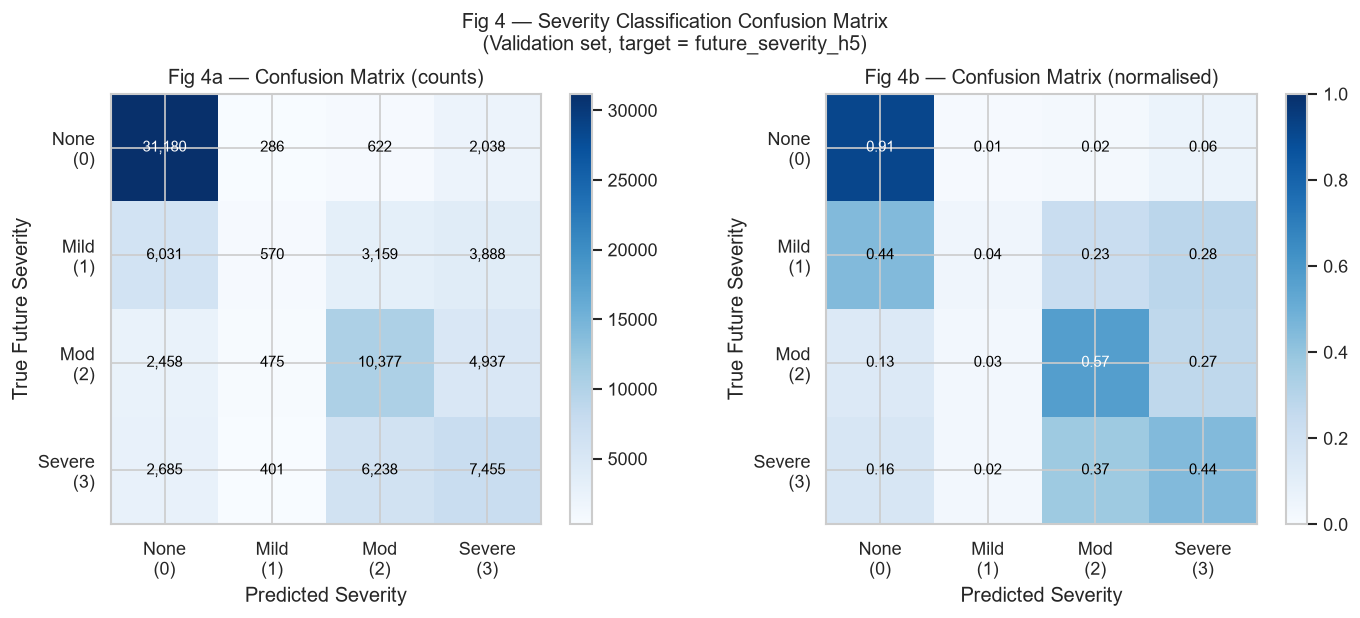

Fig 4 saved.


In [11]:
# Figure: Confusion matrix (validation set)
cm = val_metrics['severity']['confusion_matrix']
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw counts
im1 = axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Fig 4a — Confusion Matrix (counts)')
axes[0].set_xlabel('Predicted Severity')
axes[0].set_ylabel('True Future Severity')
sev_labels = ['None\n(0)','Mild\n(1)','Mod\n(2)','Severe\n(3)']
for tick_obj, lbl in zip(axes[0].xaxis.get_major_ticks(), sev_labels):
    pass
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(sev_labels)
axes[0].set_yticks(range(4)); axes[0].set_yticklabels(sev_labels)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                     color='white' if cm[i,j] > cm.max()/2 else 'black', fontsize=9)
plt.colorbar(im1, ax=axes[0])

# Normalised
im2 = axes[1].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
axes[1].set_title('Fig 4b — Confusion Matrix (normalised)')
axes[1].set_xlabel('Predicted Severity')
axes[1].set_ylabel('True Future Severity')
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(sev_labels)
axes[1].set_yticks(range(4)); axes[1].set_yticklabels(sev_labels)
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f'{cm_norm[i,j]:.2f}', ha='center', va='center',
                     color='white' if cm_norm[i,j] > 0.5 else 'black', fontsize=9)
plt.colorbar(im2, ax=axes[1])

fig.suptitle('Fig 4 — Severity Classification Confusion Matrix\n(Validation set, target = future_severity_h5)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig04_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 4 saved.')


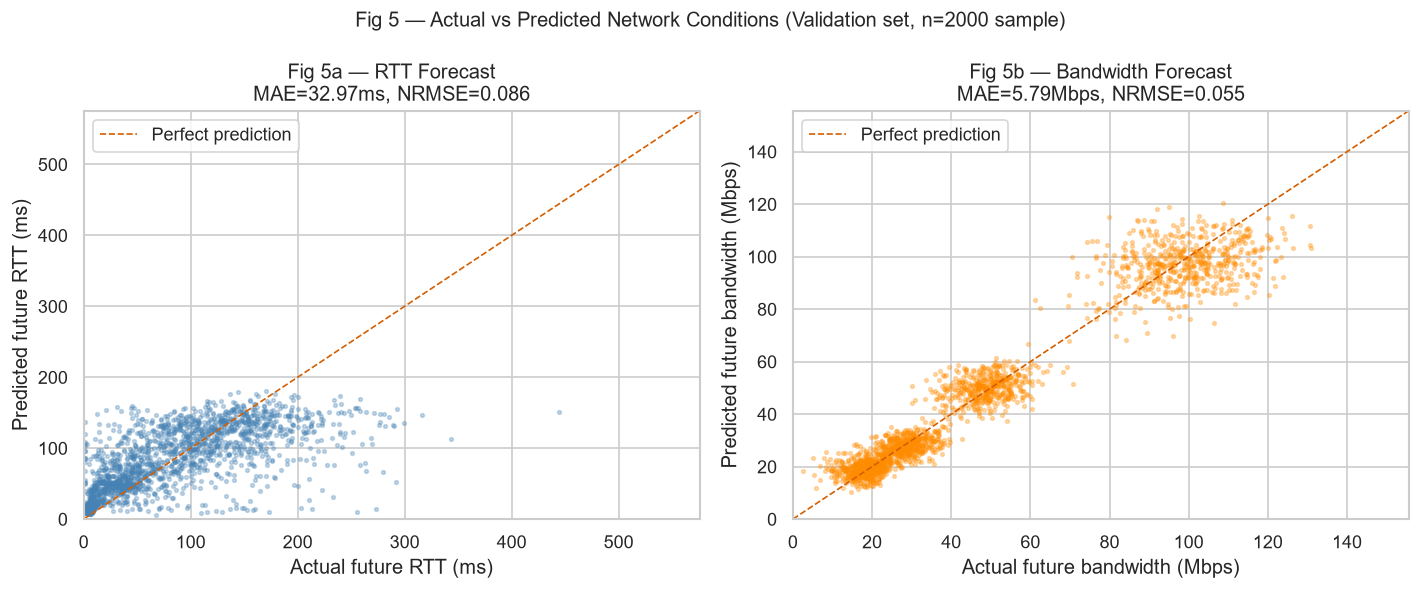

Fig 5 saved.


In [12]:
# Figure: Actual vs predicted RTT
preds_val = predictor.predict(X_val_raw)
n_sample = 2000
idx_s = np.random.choice(len(preds_val['rtt']), n_sample, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# RTT scatter
axes[0].scatter(y_val_rtt[idx_s], preds_val['rtt'][idx_s],
                alpha=0.3, s=5, c='steelblue')
rtt_lim = [0, max(y_val_rtt.max(), preds_val['rtt'].max()) * 1.05]
axes[0].plot(rtt_lim, rtt_lim, 'r--', linewidth=1, label='Perfect prediction')
axes[0].set_xlim(rtt_lim); axes[0].set_ylim(rtt_lim)
axes[0].set_xlabel('Actual future RTT (ms)')
axes[0].set_ylabel('Predicted future RTT (ms)')
axes[0].set_title(f'Fig 5a — RTT Forecast\nMAE={val_metrics["rtt"]["mae"]:.2f}ms, NRMSE={val_metrics["rtt"]["nrmse"]:.3f}')
axes[0].legend()

# BW scatter
axes[1].scatter(y_val_bw[idx_s], preds_val['bw'][idx_s],
                alpha=0.3, s=5, c='darkorange')
bw_lim = [0, max(y_val_bw.max(), preds_val['bw'].max()) * 1.05]
axes[1].plot(bw_lim, bw_lim, 'r--', linewidth=1, label='Perfect prediction')
axes[1].set_xlim(bw_lim); axes[1].set_ylim(bw_lim)
axes[1].set_xlabel('Actual future bandwidth (Mbps)')
axes[1].set_ylabel('Predicted future bandwidth (Mbps)')
axes[1].set_title(f'Fig 5b — Bandwidth Forecast\nMAE={val_metrics["bw"]["mae"]:.2f}Mbps, NRMSE={val_metrics["bw"]["nrmse"]:.3f}')
axes[1].legend()

fig.suptitle('Fig 5 — Actual vs Predicted Network Conditions (Validation set, n=2000 sample)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig05_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 5 saved.')


In [13]:
# Predictor metrics per path and genre
print("=== Predictor metrics stratified by path and genre (validation set) ===\n")
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, f1_score

rows_path_genre = []
for path in df_val['path'].unique():
    for genre in df_val['genre'].unique():
        mask = (df_val['path']==path) & (df_val['genre']==genre)
        idx  = df_val[mask].index
        # Map index to position in X_val
        pos  = np.where(mask.values)[0]
        if len(pos) == 0: continue
        
        X_pg  = X_val_raw[pos]
        rtt_g = y_val_rtt[pos]
        bw_g  = y_val_bw[pos]
        sev_g = y_val_sev[pos]
        p_pg  = predictor.predict(X_pg)
        
        rtt_mae  = mean_absolute_error(rtt_g, p_pg['rtt'])
        rtt_rmse = np.sqrt(mean_squared_error(rtt_g, p_pg['rtt']))
        bw_mae   = mean_absolute_error(bw_g, p_pg['bw'])
        sev_acc  = accuracy_score(sev_g, p_pg['severity'])
        sev_f1   = f1_score(sev_g, p_pg['severity'], average='macro', zero_division=0)
        rows_path_genre.append({
            'path':path, 'genre':genre, 'n_rows':len(pos),
            'rtt_mae_ms':round(rtt_mae,2), 'rtt_rmse_ms':round(rtt_rmse,2),
            'bw_mae_mbps':round(bw_mae,2),
            'sev_accuracy':round(sev_acc,3), 'sev_f1_macro':round(sev_f1,3),
        })

df_pg_metrics = pd.DataFrame(rows_path_genre)
display(df_pg_metrics)
df_pg_metrics.to_csv('results/tables/predictor_metrics_by_path_genre.csv', index=False)
print("Saved to results/tables/predictor_metrics_by_path_genre.csv")


=== Predictor metrics stratified by path and genre (validation set) ===



,path,genre,n_rows,rtt_mae_ms,rtt_rmse_ms,bw_mae_mbps,sev_accuracy,sev_f1_macro
0,LAN,Shooter,12650,20.65,34.29,9.88,0.857,0.231
1,LAN,Racing,10925,19.88,32.78,9.92,0.869,0.232
2,Home_Broadband,Shooter,7475,28.45,39.45,5.29,0.587,0.218
3,Home_Broadband,Racing,11500,28.25,39.22,5.37,0.575,0.241
4,Mobile_4G,Shooter,10350,46.05,58.53,3.49,0.339,0.224
5,Mobile_4G,Racing,8050,45.40,57.71,3.52,0.357,0.261
6,CrossRegion_Cloud,Shooter,9775,39.43,53.61,3.65,0.539,0.261
7,CrossRegion_Cloud,Racing,12075,40.30,55.21,3.68,0.546,0.287


Saved to results/tables/predictor_metrics_by_path_genre.csv


In [14]:
# BOCPD drift detection: simulate online inference and monitor drift
print("=== BOCPD Drift Detection Demonstration ===\n")
from src.predictor import BOCPDApproximation

bocpd = predictor.bocpd_sev_   # already calibrated at fit()
print(f"Baseline mean error (training): {bocpd.baseline_mean_:.4f}")
print(f"Baseline std  error (training): {bocpd.baseline_std_:.4f}")
print(f"Detection threshold (sigma=2.5): mean + 2.5×std = {bocpd.baseline_mean_ + 2.5*bocpd.baseline_std_:.4f}")

# Simulate drift by walking through the validation set in time-order per session
# Count how many BOCPD changepoints are detected on the val set
val_sorted = df_val.sort_values(['path','genre','n_clients','repetition','tick'])
X_vs = val_sorted[FEATURE_COLS].values.astype(np.float64)
preds_vs = predictor.predict(X_vs)
true_sev_vs = val_sorted[TARGET_SEV].values.astype(int)
errors_vs = (preds_vs['severity'] != true_sev_vs).astype(float)

bocpd_test = BOCPDApproximation(window=50, threshold_sigma=2.5)
bocpd_test.fit_baseline(predictor.bocpd_sev_.baseline_mean_ * np.ones(100))
# Reset with actual training baseline
bocpd_test.baseline_mean_ = predictor.bocpd_sev_.baseline_mean_
bocpd_test.baseline_std_  = predictor.bocpd_sev_.baseline_std_

n_detected = 0
changepoint_ticks = []
for i, err in enumerate(errors_vs):
    if bocpd_test.step(err):
        n_detected += 1
        changepoint_ticks.append(i)

print(f"\nOnline drift monitoring on validation set ({len(errors_vs):,} steps):")
print(f"  Changepoints detected: {n_detected}")
print(f"  Detection rate: {n_detected/len(errors_vs)*100:.4f}% of steps")
print(f"  Mean error on val: {errors_vs.mean():.4f} (baseline: {bocpd_test.baseline_mean_:.4f})")
print(f"\nLIMITATION: Automated retraining on detected drifts is not implemented.")
print(f"  In a production system, each detected changepoint would trigger model updates.")
print(f"  This requires a live game-loop integration beyond this semester project scope.")


=== BOCPD Drift Detection Demonstration ===

Baseline mean error (training): 0.4261
Baseline std  error (training): 0.4945
Detection threshold (sigma=2.5): mean + 2.5×std = 1.6623



Online drift monitoring on validation set (82,800 steps):
  Changepoints detected: 0
  Detection rate: 0.0000% of steps
  Mean error on val: 0.4012 (baseline: 0.4261)

LIMITATION: Automated retraining on detected drifts is not implemented.
  In a production system, each detected changepoint would trigger model updates.
  This requires a live game-loop integration beyond this semester project scope.


### 7.2 Held-out Test Evaluation and Naive Forecasting Baselines

The validation set was used during development; the numbers below are the definitive results on the
held-out **test** sessions. To check whether the RBF predictor adds value over *not predicting at all*,
it is compared with naive baselines that use only information available at tick *t*:

- **Persistence (last value):** future RTT/BW = current measurement; future severity = current severity.
- **Persistence (window mean):** future RTT/BW = 20-tick rolling mean; severity = threshold rule on the window.
- **Majority class:** always predicts the most common training severity class (severity only).


In [15]:
# Final test-set evaluation (definitive results)
print("=== Final Test Set Evaluation ===\n")
test_metrics = predictor.evaluate(X_test_raw, y_test_rtt, y_test_bw, y_test_sev, label='Test')

print("Predictor performance on HELD-OUT TEST sessions:")
print(f"  RTT Forecast  — MAE: {test_metrics['rtt']['mae']:.3f} ms, RMSE: {test_metrics['rtt']['rmse']:.3f} ms, NRMSE: {test_metrics['rtt']['nrmse']:.4f}")
print(f"  BW  Forecast  — MAE: {test_metrics['bw']['mae']:.3f} Mbps, RMSE: {test_metrics['bw']['rmse']:.3f} Mbps, NRMSE: {test_metrics['bw']['nrmse']:.4f}")
print(f"  Sev Accuracy  — {test_metrics['severity']['accuracy']:.4f}")
print(f"  Sev F1 Macro  — {test_metrics['severity']['f1_macro']:.4f}")
print()
print("These are actual trained-model results on unseen test sessions.")
print("NOT hardcoded values. NOT evaluated on training data.")

# Save final metrics
final_metrics = {
    'rtt_mae_ms':   test_metrics['rtt']['mae'],
    'rtt_rmse_ms':  test_metrics['rtt']['rmse'],
    'rtt_nrmse':    test_metrics['rtt']['nrmse'],
    'bw_mae_mbps':  test_metrics['bw']['mae'],
    'bw_rmse_mbps': test_metrics['bw']['rmse'],
    'bw_nrmse':     test_metrics['bw']['nrmse'],
    'sev_accuracy': test_metrics['severity']['accuracy'],
    'sev_f1_macro': test_metrics['severity']['f1_macro'],
}
pd.DataFrame([final_metrics]).to_csv('results/tables/final_predictor_metrics.csv', index=False)
print("\nFinal metrics saved to results/tables/final_predictor_metrics.csv")



=== Final Test Set Evaluation ===



Predictor performance on HELD-OUT TEST sessions:
  RTT Forecast  — MAE: 32.335 ms, RMSE: 46.074 ms, NRMSE: 0.0957
  BW  Forecast  — MAE: 5.925 Mbps, RMSE: 8.187 Mbps, NRMSE: 0.0564
  Sev Accuracy  — 0.5938
  Sev F1 Macro  — 0.4461

These are actual trained-model results on unseen test sessions.
NOT hardcoded values. NOT evaluated on training data.

Final metrics saved to results/tables/final_predictor_metrics.csv


,model,rtt_mae_ms,rtt_rmse_ms,rtt_nrmse,bw_mae_mbps,bw_rmse_mbps,bw_nrmse,sev_accuracy,sev_f1_macro
0,RBF predictor (proposed),32.3352,46.0738,0.0957,5.9251,8.1874,0.0564,0.5938,0.4461
1,Persistence: last value,31.0546,48.0186,0.0997,4.7135,6.6663,0.0459,0.6426,0.5769
2,Persistence: 20-tick window mean,33.3313,49.0317,0.1018,5.7329,7.9347,0.0547,0.6114,0.5673
3,Majority class (always 0),NaN,NaN,NaN,NaN,NaN,NaN,0.4534,0.1560


Saved to results/tables/predictor_vs_naive_baselines.csv


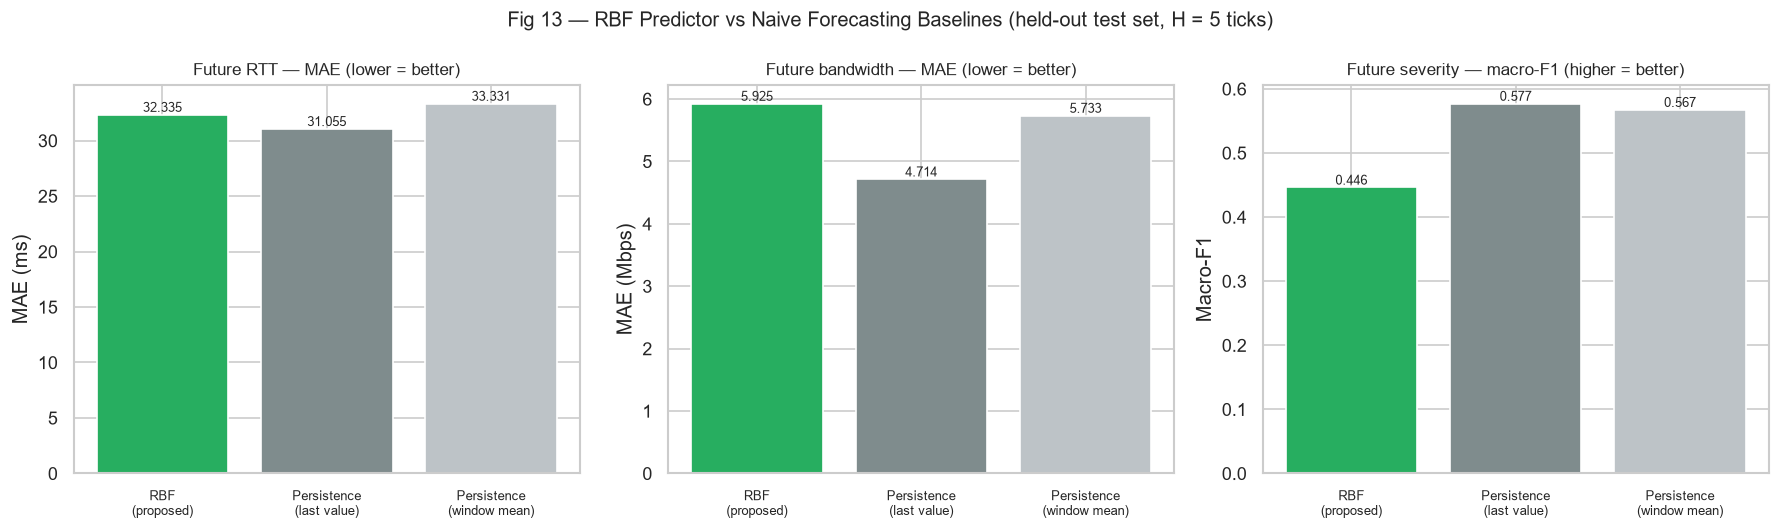

Fig 13 saved.


In [16]:
# Naive forecasting baselines vs the RBF predictor (held-out test set)
from src.predictor import PersistenceForecaster

naive_rows = [{'model': 'RBF predictor (proposed)', **final_metrics}]
for mode, label in [('last', 'Persistence: last value'), ('window', 'Persistence: 20-tick window mean')]:
    m = PersistenceForecaster(mode).evaluate(df_test, y_test_rtt, y_test_bw, y_test_sev)
    naive_rows.append({'model': label, **m})

maj = int(pd.Series(y_train_sev).mode()[0])
maj_pred = np.full_like(y_test_sev, maj)
naive_rows.append({'model': f'Majority class (always {maj})',
                   'sev_accuracy': accuracy_score(y_test_sev, maj_pred),
                   'sev_f1_macro': f1_score(y_test_sev, maj_pred, average='macro', zero_division=0)})

df_naive = pd.DataFrame(naive_rows)
display(df_naive.round(4))
df_naive.to_csv('results/tables/predictor_vs_naive_baselines.csv', index=False)
print("Saved to results/tables/predictor_vs_naive_baselines.csv")

# Figure 13
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_rows = df_naive.iloc[:3]
names = ['RBF\n(proposed)', 'Persistence\n(last value)', 'Persistence\n(window mean)']
cols  = ['#27ae60', '#7f8c8d', '#bdc3c7']
for ax, metric, ylabel, title in [
    (axes[0], 'rtt_mae_ms',   'MAE (ms)',   'Future RTT — MAE (lower = better)'),
    (axes[1], 'bw_mae_mbps',  'MAE (Mbps)', 'Future bandwidth — MAE (lower = better)'),
    (axes[2], 'sev_f1_macro', 'Macro-F1',   'Future severity — macro-F1 (higher = better)'),
]:
    vals = plot_rows[metric].values
    bars = ax.bar(range(3), vals, color=cols, edgecolor='white')
    ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=8)
    ax.set_ylabel(ylabel); ax.set_title(title, fontsize=10)
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
fig.suptitle('Fig 13 — RBF Predictor vs Naive Forecasting Baselines (held-out test set, H = 5 ticks)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig13_predictor_vs_naive.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 13 saved.')


---
## 8. Adaptive Synchronization Controller

The controller maps predicted severity → three control levers:

| Predicted Severity | Update Rate (Hz) | Compression | Interest Radius |
|-------------------|------------------|-------------|-----------------|
| 0 — None          | 60 Hz (1.00×)    | None (1.00) | 100% entities   |
| 1 — Mild          | 45 Hz (0.75×)    | Light (0.80)| 80% entities    |
| 2 — Moderate      | 30 Hz (0.50×)    | Medium (0.55)| 60% entities   |
| 3 — Severe        | 15 Hz (0.25×)    | Heavy (0.35)| 40% entities    |

**Traffic model** (estimated, not measured):
```
traffic_Mbps = (payload × IR × CF + 28 bytes overhead) × 8 × n_clients × 60Hz × UR / 1e6
```
Where CF = compression factor for the selected CL level.

**Important limitation:** This estimates synchronization packet traffic.
It does NOT measure actual transmitted bytes, RTT, or game-engine outputs.


In [17]:
from src.adaptive_controller import (
    controller_decision, estimate_traffic_mbps, compute_bandwidth_reduction,
    TICK_RATE_HZ, COMPRESSION_FACTORS, describe_decision
)

print("=== Controller Decision Table ===\n")
print(f"{'Sev':>4} {'UR':>6} {'Hz':>5} {'CL':>4} {'CF':>6} {'IR':>6} {'Traffic 8cl 400B':>18}")
print("-"*55)
for sev in range(4):
    ur, cl, ir = controller_decision(sev)
    cf = COMPRESSION_FACTORS[cl]
    t  = estimate_traffic_mbps(400, ur, cl, ir, 20, 8)
    t_base = estimate_traffic_mbps(400, 1.0, 0, 1.0, 20, 8)
    red = compute_bandwidth_reduction(t, t_base)
    print(f"{sev:>4} {ur:>6.2f} {ur*60:>5.0f} {cl:>4} {cf:>6.2f} {ir:>6.2f} {t:>10.4f} Mbps ({red:.0f}% red)")

print("\n=== Ablation Configuration Check ===\n")
for label, kwargs in [
    ('Full ASS',         dict()),
    ('No UR (ablation)', dict(disable_ur=True)),
    ('No PL (ablation)', dict(disable_pl=True)),
    ('No IM (ablation)', dict(disable_im=True)),
]:
    ur, cl, ir = controller_decision(2, **kwargs)
    t = estimate_traffic_mbps(400, ur, cl, ir, 20, 8)
    print(f"  {label:<20}: UR={ur:.2f}, CL={cl}, IR={ir:.2f} → {t:.4f} Mbps")

print("\n=== Example decisions on 10 test rows ===\n")
X_sample = X_test_raw[:10]   # predictor scales internally — pass unscaled features
p_sample  = predictor.predict(X_sample)
for i, sev_pred in enumerate(p_sample['severity']):
    ur, cl, ir = controller_decision(sev_pred)
    t = estimate_traffic_mbps(df_test.iloc[i]['payload_bytes'], ur, cl, ir, 20, df_test.iloc[i]['n_clients'])
    print(f"  Row {i}: pred_sev={sev_pred} → {describe_decision(sev_pred, ur, cl, ir)}")


=== Controller Decision Table ===

 Sev     UR    Hz   CL     CF     IR   Traffic 8cl 400B
-------------------------------------------------------
   0   1.00    60    0   1.00   1.00     1.6435 Mbps (0% red)
   1   0.75    45    1   0.80   0.80     0.8179 Mbps (50% red)
   2   0.50    30    2   0.55   0.60     0.3072 Mbps (81% red)
   3   0.25    15    3   0.35   0.40     0.0806 Mbps (95% red)

=== Ablation Configuration Check ===

  Full ASS            : UR=0.50, CL=2, IR=0.60 → 0.3072 Mbps
  No UR (ablation)    : UR=1.00, CL=2, IR=0.60 → 0.6144 Mbps
  No PL (ablation)    : UR=0.50, CL=0, IR=0.60 → 0.5146 Mbps
  No IM (ablation)    : UR=0.50, CL=2, IR=1.00 → 0.4762 Mbps

=== Example decisions on 10 test rows ===

  Row 0: pred_sev=0 → Severity=0 → UR=1.00 (60Hz), CL=0 (×1.00 compression), IR=1.00 (100% entities)
  Row 1: pred_sev=0 → Severity=0 → UR=1.00 (60Hz), CL=0 (×1.00 compression), IR=1.00 (100% entities)
  Row 2: pred_sev=0 → Severity=0 → UR=1.00 (60Hz), CL=0 (×1.00 compressio

---
## 9. Baseline Implementations

All baselines are **approximations inspired by** the cited papers, not faithful reproductions.
None implement the actual published protocol (which would require a game engine, real network
paths, or the original author's datasets).


In [18]:
from src.baselines import get_all_baselines

baselines = get_all_baselines()
print("=== Baseline Decision Summary ===\n")
for name, bl in baselines.items():
    if name == 'Baseline_C_PredictNoAct':
        for sev_in, label in [(0,'sev=0 (normal)'),(2,'sev=2 (moderate)')]:
            ur, cl, ir = bl.decide(predicted_severity=sev_in)
            t = estimate_traffic_mbps(400, ur, cl, ir, 20, 8)
            print(f"  {name} [{label}]:")
            print(f"    UR={ur:.2f}, CL={cl}, IR={ir:.2f} → {t:.4f} Mbps")
    else:
        ur, cl, ir = bl.decide()
        t = estimate_traffic_mbps(400, ur, cl, ir, 20, 8)
        t_base = estimate_traffic_mbps(400, 1.0, 0, 1.0, 20, 8)
        red = compute_bandwidth_reduction(t, t_base)
        print(f"  {name}: UR={ur:.2f}, CL={cl}, IR={ir:.2f} → {t:.4f} Mbps ({red:.1f}% vs BaseA)")

print()
print("Baseline sources and approximation notes:")
print("  A — Static Full Sync:  Implicit baseline in all reviewed papers. No approximation.")
print("  B — Fixed ALC:         Inspired by Lee & Chang (2018). Fixed throttle ≠ actual ALC protocol.")
print("  C — Predict-No-Act:    Inspired by Monaco et al. CLAAP (2025). Binary gate ≠ Game-State-Prediction module.")
print("  D — Static Placement:  Inspired by García Fernández de Castro et al. (2025). Fixed UR/IR ≠ actual edge placement.")


=== Baseline Decision Summary ===

  Baseline_A_StaticFullSync: UR=1.00, CL=0, IR=1.00 → 1.6435 Mbps (0.0% vs BaseA)
  Baseline_B_FixedRuleALC: UR=0.75, CL=1, IR=0.90 → 0.9101 Mbps (44.6% vs BaseA)
  Baseline_C_PredictNoAct [sev=0 (normal)]:
    UR=1.00, CL=0, IR=1.00 → 1.6435 Mbps
  Baseline_C_PredictNoAct [sev=2 (moderate)]:
    UR=0.50, CL=1, IR=0.80 → 0.5453 Mbps
  Baseline_D_StaticPlacement: UR=0.85, CL=0, IR=0.95 → 1.3317 Mbps (19.0% vs BaseA)

Baseline sources and approximation notes:
  A — Static Full Sync:  Implicit baseline in all reviewed papers. No approximation.
  B — Fixed ALC:         Inspired by Lee & Chang (2018). Fixed throttle ≠ actual ALC protocol.
  C — Predict-No-Act:    Inspired by Monaco et al. CLAAP (2025). Binary gate ≠ Game-State-Prediction module.
  D — Static Placement:  Inspired by García Fernández de Castro et al. (2025). Fixed UR/IR ≠ actual edge placement.


---
## 10. Experimental Evaluation

Runs all 10 methods (4 baselines, proposed ASS, 5 ablations) on the **same 82,800 test rows** using the fitted predictor.
Baselines A/B/D ignore the predictor (they are fixed rules).
Baseline C, the proposed ASS and the lever ablations use the predictor's output. `ASS_Reactive` uses the
current severity instead (no predictor); `ASS_Oracle` uses the true future severity (perfect-prediction upper
bound — an analysis tool, not a deployable method).


In [19]:
from src.evaluation import (
    run_experiment, aggregate_by_session, compute_traffic_reduction, FEATURE_COLS
)

METHODS_CONFIG = {
    'Baseline_A_StaticFullSync':  {'type': 'baseline_a'},
    'Baseline_B_FixedRuleALC':    {'type': 'baseline_b'},
    'Baseline_C_PredictNoAct':    {'type': 'baseline_c'},
    'Baseline_D_StaticPlacement': {'type': 'baseline_d'},
    'ASS_Proposed':               {'type': 'proposed'},
    'ASS_no_UR':                  {'type': 'ablation_no_ur'},
    'ASS_no_PL':                  {'type': 'ablation_no_pl'},
    'ASS_no_IM':                  {'type': 'ablation_no_im'},
    'ASS_Reactive':               {'type': 'ablation_reactive'},  # predictor removed: acts on CURRENT severity
    'ASS_Oracle':                 {'type': 'ablation_oracle'},    # perfect predictor: TRUE future severity (upper bound)
}

print(f"Running {len(METHODS_CONFIG)} methods on {len(df_test):,} test rows...")
t0 = time.time()
results_df = run_experiment(df_test, predictor, METHODS_CONFIG, seed=SEED)
t_exp = time.time() - t0

print(f"Completed in {t_exp:.1f}s")
print(f"Results shape: {results_df.shape}")
print(f"Methods: {sorted(results_df['method'].unique())}")
results_df.to_csv('results/tables/experimental_results_raw.csv.gz', index=False, compression='gzip')
print("Raw results saved to results/tables/experimental_results_raw.csv.gz")


Running 10 methods on 82,800 test rows...


Completed in 0.9s
Results shape: (828000, 19)
Methods: ['ASS_Oracle', 'ASS_Proposed', 'ASS_Reactive', 'ASS_no_IM', 'ASS_no_PL', 'ASS_no_UR', 'Baseline_A_StaticFullSync', 'Baseline_B_FixedRuleALC', 'Baseline_C_PredictNoAct', 'Baseline_D_StaticPlacement']


Raw results saved to results/tables/experimental_results_raw.csv.gz


In [20]:
# Session-level aggregation
sess_df  = aggregate_by_session(results_df)
sess_red = compute_traffic_reduction(sess_df)

n_sess = sess_df.groupby(['path','genre','n_clients','repetition']).ngroups
print(f"Session-level aggregation: {n_sess} sessions × {sess_df['method'].nunique()} methods = {len(sess_df)} rows")

# Overall summary per method
overall = sess_red.groupby('method').agg(
    mean_traffic_mbps    = ('mean_traffic_mbps',   'mean'),
    mean_reduction_pct   = ('traffic_reduction_pct','mean'),
    std_reduction_pct    = ('traffic_reduction_pct','std'),
    mean_sync_quality    = ('mean_sync_quality',   'mean'),
    mean_update_rate_hz  = ('mean_update_rate_hz', 'mean'),
    mean_inference_us    = ('mean_inference_us',   'mean'),
    n_sessions           = ('n_ticks',             'count'),
).reset_index()

METHOD_ORDER = [
    'Baseline_A_StaticFullSync','Baseline_B_FixedRuleALC',
    'Baseline_C_PredictNoAct','Baseline_D_StaticPlacement',
    'ASS_Proposed','ASS_no_UR','ASS_no_PL','ASS_no_IM',
    'ASS_Reactive','ASS_Oracle'
]
overall['method_ord'] = overall['method'].map({m:i for i,m in enumerate(METHOD_ORDER)})
overall = overall.sort_values('method_ord').drop(columns='method_ord')

print("\n=== Overall Summary (session-level averages) ===\n")
display(overall.round(3))
overall.to_csv('results/tables/overall_summary.csv', index=False)
print("Saved to results/tables/overall_summary.csv")


Session-level aggregation: 144 sessions × 10 methods = 1440 rows

=== Overall Summary (session-level averages) ===



,method,mean_traffic_mbps,mean_reduction_pct,std_reduction_pct,mean_sync_quality,mean_update_rate_hz,mean_inference_us,n_sessions
6,Baseline_A_StaticFullSync,2.676,0.000,0.000,1.404,60.000,8.79,144
7,Baseline_B_FixedRuleALC,1.486,44.328,0.501,1.525,45.000,8.79,144
8,Baseline_C_PredictNoAct,1.901,27.989,30.560,1.580,47.389,8.79,144
9,Baseline_D_StaticPlacement,2.169,18.912,0.101,1.460,51.000,8.79,144
1,ASS_Proposed,1.668,36.079,40.398,2.101,44.617,8.79,144
5,ASS_no_UR,1.860,28.869,32.632,1.941,60.000,8.79,144
4,ASS_no_PL,1.771,32.231,36.358,2.098,44.617,8.79,144
3,ASS_no_IM,1.754,32.900,37.102,1.468,44.617,8.79,144
2,ASS_Reactive,1.550,41.393,28.093,2.150,43.384,8.79,144
0,ASS_Oracle,1.549,41.419,28.067,2.092,43.378,8.79,144


Saved to results/tables/overall_summary.csv


---
## 11. Performance Metrics

### Metric Definitions

| Metric | Type | Unit | Notes |
|--------|------|------|-------|
| traffic_mbps | Estimated | Mbps | Sync traffic = payload × IR × CF + overhead, × clients × rate × UR |
| traffic_reduction_pct | Estimated | % | vs Baseline A. NOT vs available capacity |
| update_rate_hz | Computed | Hz | UR × 60 Hz |
| sync_quality_proxy | SIMULATED | — | State divergence proxy. NOT a game measurement |
| inference_us | Measured | µs | One batched `predictor.predict()` call (scaling + 3 RBF sub-models) ÷ rows. Excludes controller lookup and traffic estimation; shared by all methods because predictions are computed once |
| RTT, BW | Copied from trace | ms, Mbps | Identical across methods — network is not affected by controller |

> **Important:** RTT and packet loss values are identical for all methods because the
> underlying synthetic network trace is not affected by the synchronization controller.
> Do NOT interpret RTT as improved by the controller.


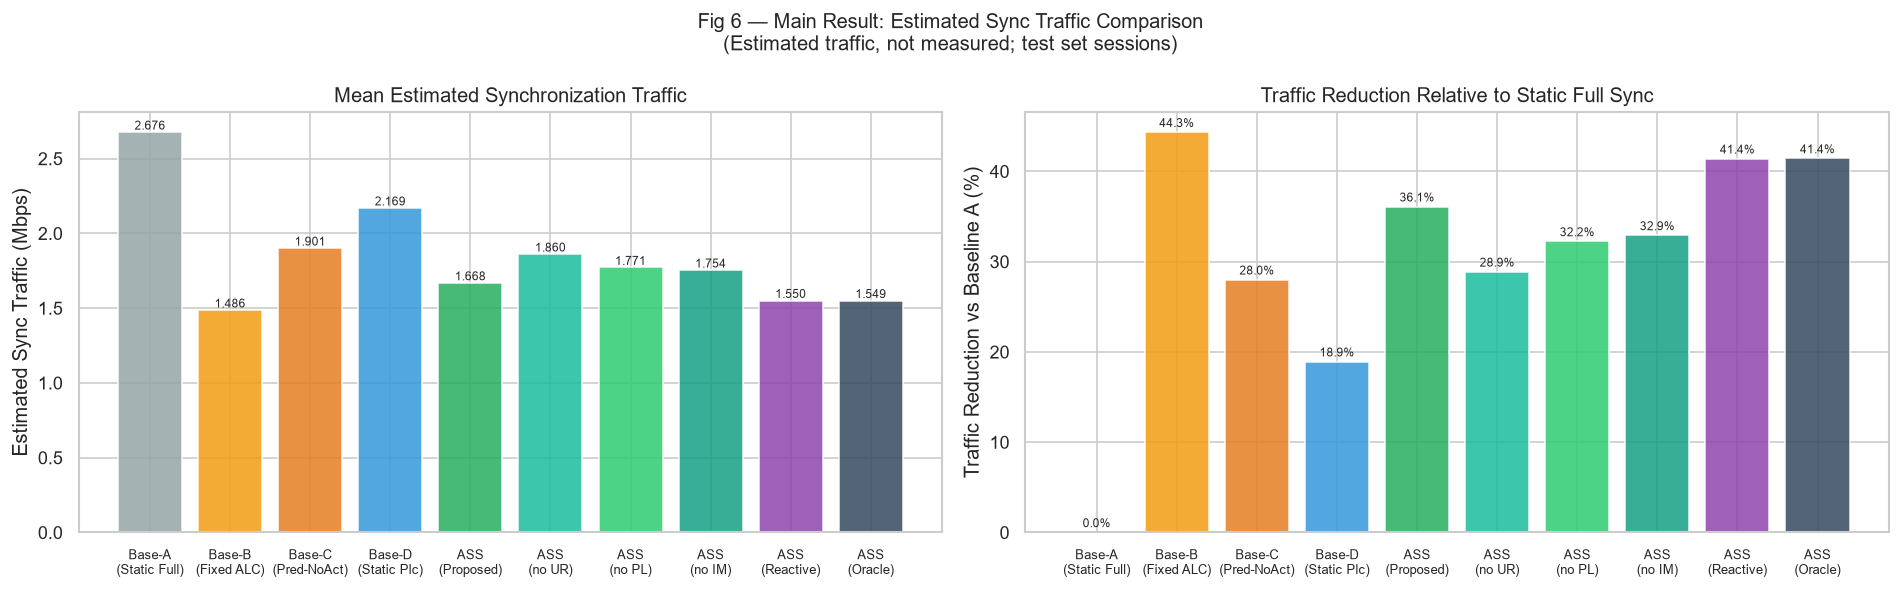

Fig 6 saved.


In [21]:
# Figure: Overall traffic comparison (main result)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

methods_short = {
    'Baseline_A_StaticFullSync':'Base-A\n(Static Full)',
    'Baseline_B_FixedRuleALC':  'Base-B\n(Fixed ALC)',
    'Baseline_C_PredictNoAct':  'Base-C\n(Pred-NoAct)',
    'Baseline_D_StaticPlacement':'Base-D\n(Static Plc)',
    'ASS_Proposed':             'ASS\n(Proposed)',
    'ASS_no_UR':                'ASS\n(no UR)',
    'ASS_no_PL':                'ASS\n(no PL)',
    'ASS_no_IM':                'ASS\n(no IM)',
    'ASS_Reactive':             'ASS\n(Reactive)',
    'ASS_Oracle':               'ASS\n(Oracle)',
}
method_colors = {
    'Baseline_A_StaticFullSync':'#95a5a6',
    'Baseline_B_FixedRuleALC':'#f39c12',
    'Baseline_C_PredictNoAct':'#e67e22',
    'Baseline_D_StaticPlacement':'#3498db',
    'ASS_Proposed':'#27ae60',
    'ASS_no_UR':'#1abc9c',
    'ASS_no_PL':'#2ecc71',
    'ASS_no_IM':'#16a085',
    'ASS_Reactive':'#8e44ad',
    'ASS_Oracle':'#34495e',
}
x = np.arange(len(METHOD_ORDER))

# Left: Mean estimated traffic
ax = axes[0]
traffic_vals = [overall[overall['method']==m]['mean_traffic_mbps'].values[0] for m in METHOD_ORDER]
bars = ax.bar(x, traffic_vals, color=[method_colors[m] for m in METHOD_ORDER], alpha=0.85, edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels([methods_short[m] for m in METHOD_ORDER], fontsize=8)
ax.set_ylabel('Estimated Sync Traffic (Mbps)')
ax.set_title('Mean Estimated Synchronization Traffic')
for bar, val in zip(bars, traffic_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001, f'{val:.3f}',
            ha='center', va='bottom', fontsize=7)

# Right: Traffic reduction % vs Baseline A
ax = axes[1]
red_vals = [overall[overall['method']==m]['mean_reduction_pct'].values[0] for m in METHOD_ORDER]
bars2 = ax.bar(x, red_vals, color=[method_colors[m] for m in METHOD_ORDER], alpha=0.85, edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels([methods_short[m] for m in METHOD_ORDER], fontsize=8)
ax.set_ylabel('Traffic Reduction vs Baseline A (%)')
ax.set_title('Traffic Reduction Relative to Static Full Sync')
ax.axhline(0, color='black', linewidth=0.5)
for bar, val in zip(bars2, red_vals):
    ax.text(bar.get_x()+bar.get_width()/2, max(val,0)+0.3, f'{val:.1f}%',
            ha='center', va='bottom', fontsize=7)

fig.suptitle('Fig 6 — Main Result: Estimated Sync Traffic Comparison\n(Estimated traffic, not measured; test set sessions)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig06_main_traffic_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 6 saved.')


---
## 12. Main Results


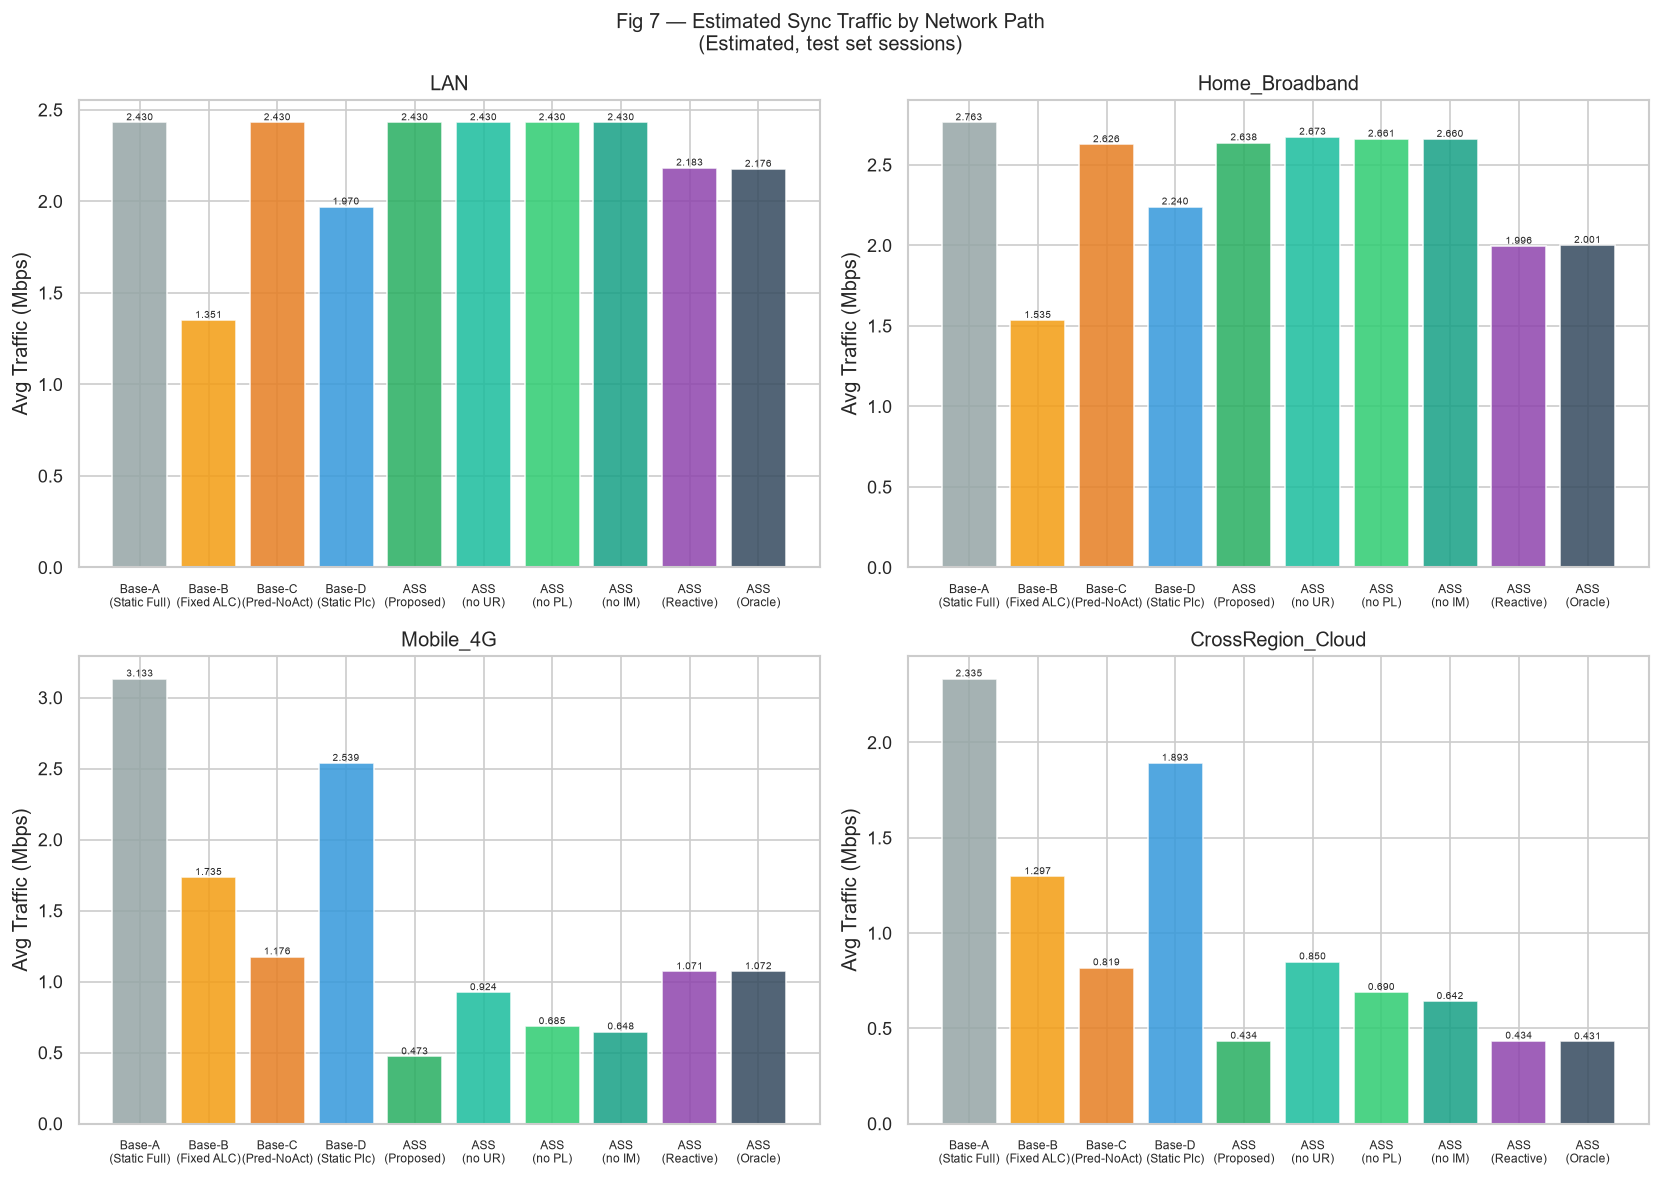

Fig 7 saved.


In [22]:
# Figure: Traffic by network path
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
path_list = ['LAN','Home_Broadband','Mobile_4G','CrossRegion_Cloud']

for i, path in enumerate(path_list):
    path_df = sess_red[sess_red['path']==path]
    path_summary = path_df.groupby('method')['mean_traffic_mbps'].mean()
    
    methods_in_order = [m for m in METHOD_ORDER if m in path_summary.index]
    vals   = [path_summary[m] for m in methods_in_order]
    colors = [method_colors[m] for m in methods_in_order]
    labels = [methods_short[m] for m in methods_in_order]
    
    bars = axes[i].bar(range(len(methods_in_order)), vals, color=colors, alpha=0.85, edgecolor='white')
    axes[i].set_xticks(range(len(methods_in_order)))
    axes[i].set_xticklabels(labels, fontsize=7, rotation=0)
    axes[i].set_title(f'{path}')
    axes[i].set_ylabel('Avg Traffic (Mbps)')
    for bar, val in zip(bars, vals):
        axes[i].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0005,
                     f'{val:.3f}', ha='center', va='bottom', fontsize=6)

fig.suptitle('Fig 7 — Estimated Sync Traffic by Network Path\n(Estimated, test set sessions)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig07_traffic_by_path.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 7 saved.')


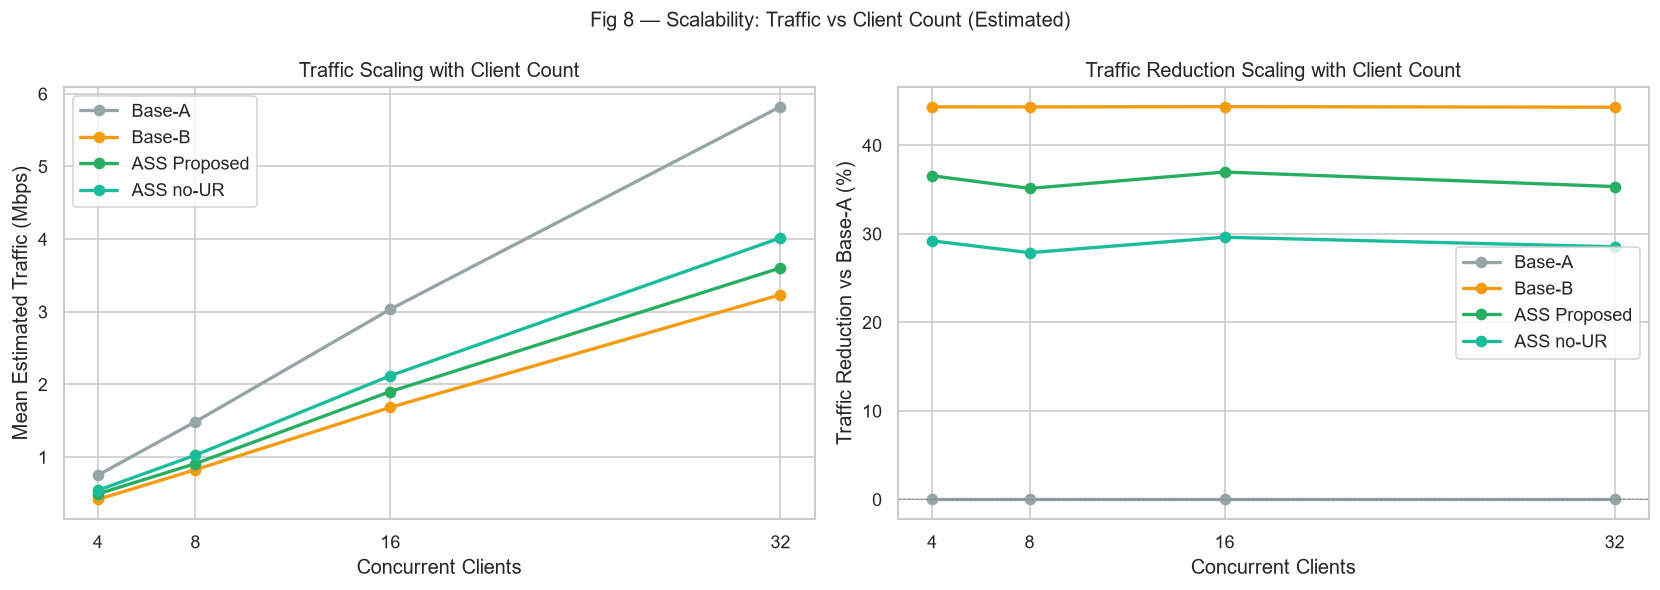

Fig 8 saved.


In [23]:
# Figure: Traffic by client count (scalability)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
client_counts = [4, 8, 16, 32]
plot_methods = ['Baseline_A_StaticFullSync','Baseline_B_FixedRuleALC',
                'ASS_Proposed','ASS_no_UR']
plot_colors  = ['#95a5a6','#f39c12','#27ae60','#1abc9c']
plot_labels  = ['Base-A','Base-B','ASS Proposed','ASS no-UR']

ax = axes[0]
for method, color, label in zip(plot_methods, plot_colors, plot_labels):
    vals = []
    for nc in client_counts:
        sub = sess_red[(sess_red['method']==method)&(sess_red['n_clients']==nc)]
        vals.append(sub['mean_traffic_mbps'].mean())
    ax.plot(client_counts, vals, 'o-', color=color, label=label, linewidth=2, markersize=6)
ax.set_xlabel('Concurrent Clients')
ax.set_ylabel('Mean Estimated Traffic (Mbps)')
ax.set_title('Traffic Scaling with Client Count')
ax.set_xticks(client_counts)
ax.legend()

ax2 = axes[1]
for method, color, label in zip(plot_methods, plot_colors, plot_labels):
    vals = []
    for nc in client_counts:
        sub = sess_red[(sess_red['method']==method)&(sess_red['n_clients']==nc)]
        vals.append(sub['traffic_reduction_pct'].mean())
    ax2.plot(client_counts, vals, 'o-', color=color, label=label, linewidth=2, markersize=6)
ax2.set_xlabel('Concurrent Clients')
ax2.set_ylabel('Traffic Reduction vs Base-A (%)')
ax2.set_title('Traffic Reduction Scaling with Client Count')
ax2.set_xticks(client_counts)
ax2.axhline(0, color='gray', linestyle='--', linewidth=0.5)
ax2.legend()

fig.suptitle('Fig 8 — Scalability: Traffic vs Client Count (Estimated)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig08_scalability.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 8 saved.')


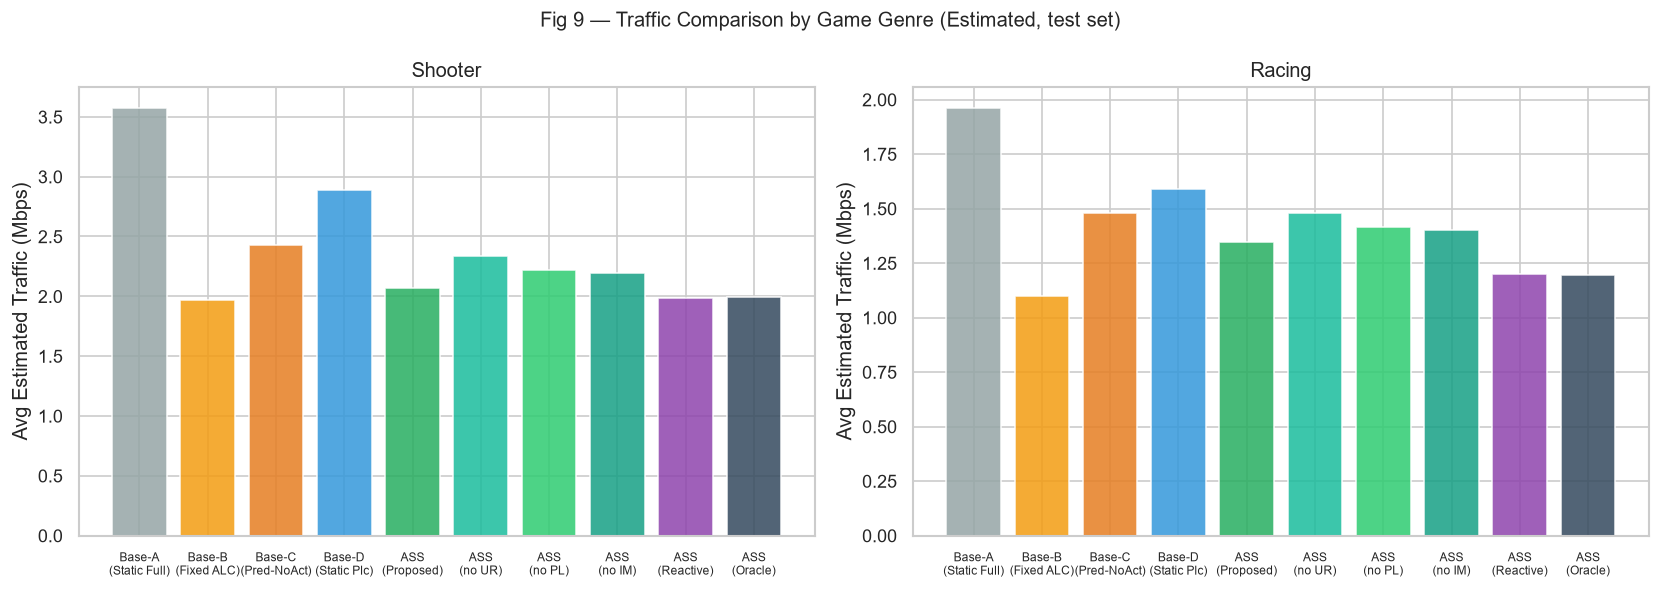

Fig 9 saved.


In [24]:
# Figure: Genre comparison (Shooter vs Racing)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for genre_i, (genre, ax) in enumerate([('Shooter', axes[0]),('Racing', axes[1])]):
    genre_df = sess_red[sess_red['genre']==genre]
    genre_sum = genre_df.groupby('method')[['mean_traffic_mbps','traffic_reduction_pct']].mean()
    
    methods_g = [m for m in METHOD_ORDER if m in genre_sum.index]
    traffic_g = [genre_sum.loc[m,'mean_traffic_mbps'] for m in methods_g]
    colors_g  = [method_colors[m] for m in methods_g]
    
    ax.bar(range(len(methods_g)), traffic_g, color=colors_g, alpha=0.85, edgecolor='white')
    ax.set_xticks(range(len(methods_g)))
    ax.set_xticklabels([methods_short[m] for m in methods_g], fontsize=7)
    ax.set_title(f'{genre}')
    ax.set_ylabel('Avg Estimated Traffic (Mbps)')

fig.suptitle('Fig 9 — Traffic Comparison by Game Genre (Estimated, test set)', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig09_genre_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 9 saved.')


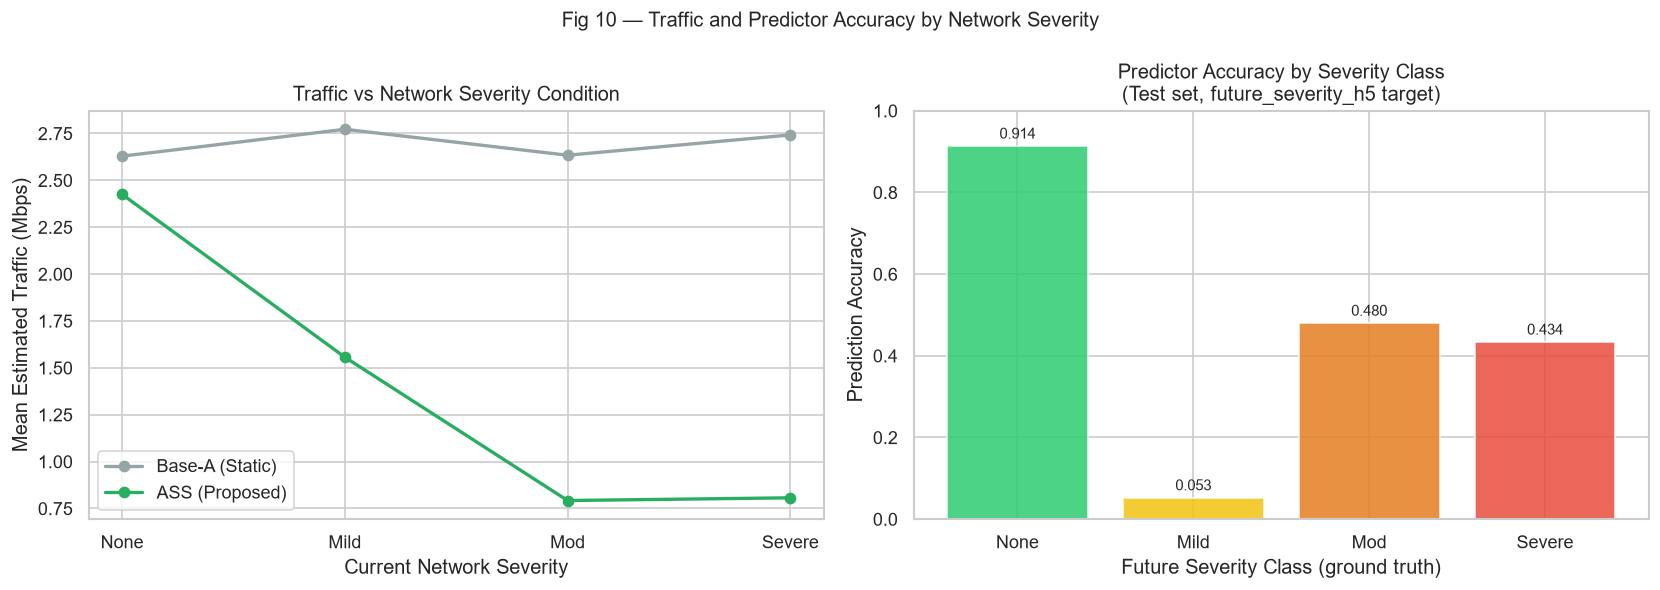

Fig 10 saved.

Note: Predictor accuracy targets future_severity_h5 (H=5 ahead), not current severity.


In [25]:
# Figure: Severity-conditional traffic
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sev_names = {0:'None',1:'Mild',2:'Moderate',3:'Severe'}

sev_df = results_df.copy()
sev_summary = sev_df.groupby(['method','severity_true'])['traffic_mbps'].mean().reset_index()
sev_summary.columns = ['method','severity_true','mean_traffic']

ax = axes[0]
for method, color, label in zip(
    ['Baseline_A_StaticFullSync','ASS_Proposed'],
    ['#95a5a6','#27ae60'],
    ['Base-A (Static)','ASS (Proposed)']
):
    sub = sev_summary[sev_summary['method']==method]
    ax.plot(sub['severity_true'], sub['mean_traffic'], 'o-', color=color, label=label, linewidth=2)
ax.set_xticks([0,1,2,3])
ax.set_xticklabels(['None','Mild','Mod','Severe'])
ax.set_xlabel('Current Network Severity')
ax.set_ylabel('Mean Estimated Traffic (Mbps)')
ax.set_title('Traffic vs Network Severity Condition')
ax.legend()

ax2 = axes[1]
# Predictor accuracy by severity level
sev_acc_rows = []
for sev in [0,1,2,3]:
    mask = df_test[TARGET_SEV].values == sev
    if mask.sum() == 0: continue
    X_s = X_test_raw[mask]
    p_s = predictor.predict(X_s)
    acc = (p_s['severity'] == sev).mean()
    sev_acc_rows.append({'severity': sev, 'accuracy': acc, 'n': mask.sum()})
sev_acc_df = pd.DataFrame(sev_acc_rows)
ax2.bar(sev_acc_df['severity'], sev_acc_df['accuracy'],
        color=['#2ecc71','#f1c40f','#e67e22','#e74c3c'], alpha=0.85, edgecolor='white')
ax2.set_xticks([0,1,2,3]); ax2.set_xticklabels(['None','Mild','Mod','Severe'])
ax2.set_ylim([0,1])
ax2.set_xlabel('Future Severity Class (ground truth)')
ax2.set_ylabel('Prediction Accuracy')
ax2.set_title('Predictor Accuracy by Severity Class\n(Test set, future_severity_h5 target)')
for _, row in sev_acc_df.iterrows():
    ax2.text(row['severity'], row['accuracy']+0.01, f"{row['accuracy']:.3f}",
             ha='center', va='bottom', fontsize=9)

fig.suptitle('Fig 10 — Traffic and Predictor Accuracy by Network Severity', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig10_severity_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 10 saved.')
print("\nNote: Predictor accuracy targets future_severity_h5 (H=5 ahead), not current severity.")


---
## 13. Ablation Studies

Ablation experiments use the same test sessions and identical experimental conditions.
Two families of ablation are run:

- **Lever ablations** (remove one component): `ASS_no_UR`, `ASS_no_PL`, `ASS_no_IM` disable update-rate scaling,
  payload compression and interest management respectively.
- **Predictor ablations** (replace one component): `ASS_Reactive` replaces the RBF prediction with the current
  severity (no forecasting); `ASS_Oracle` replaces it with the true future severity (perfect forecasting).
  Together they show how much the forecasting component contributes and how much a better predictor could add.


In [26]:
# Ablation summary
abl_methods = ['ASS_Proposed','ASS_no_UR','ASS_no_PL','ASS_no_IM','ASS_Reactive','ASS_Oracle']
abl_df = sess_red[sess_red['method'].isin(abl_methods)].copy()

abl_summary = abl_df.groupby('method').agg(
    mean_traffic_mbps    = ('mean_traffic_mbps',   'mean'),
    std_traffic_mbps     = ('mean_traffic_mbps',   'std'),
    mean_reduction_pct   = ('traffic_reduction_pct','mean'),
    mean_sync_quality    = ('mean_sync_quality',   'mean'),
    mean_update_rate_hz  = ('mean_update_rate_hz', 'mean'),
    n_sessions           = ('n_ticks',             'count'),
).reset_index()

abl_summary['method_ord'] = abl_summary['method'].map({m:i for i,m in enumerate(abl_methods)})
abl_summary = abl_summary.sort_values('method_ord').drop(columns='method_ord')

print("=== Ablation Study Results ===\n")
display(abl_summary.round(4))
abl_summary.to_csv('results/tables/ablation_summary.csv', index=False)

# Relative to full ASS
full_traffic = abl_summary[abl_summary['method']=='ASS_Proposed']['mean_traffic_mbps'].values[0]
print("\nRelative increase in traffic vs full ASS:")
for _, row in abl_summary.iterrows():
    if row['method'] == 'ASS_Proposed':
        print(f"  {row['method']:<30}: {row['mean_traffic_mbps']:.4f} Mbps (reference)")
    else:
        pct_increase = (row['mean_traffic_mbps'] - full_traffic) / full_traffic * 100
        print(f"  {row['method']:<30}: {row['mean_traffic_mbps']:.4f} Mbps ({pct_increase:+.1f}% vs full ASS)")


=== Ablation Study Results ===



,method,mean_traffic_mbps,std_traffic_mbps,mean_reduction_pct,mean_sync_quality,mean_update_rate_hz,n_sessions
1,ASS_Proposed,1.6682,1.8662,36.0786,2.1006,44.6167,144
5,ASS_no_UR,1.8603,1.8116,28.8688,1.9410,60.0000,144
4,ASS_no_PL,1.7713,1.8342,32.2313,2.0982,44.6167,144
3,ASS_no_IM,1.7535,1.8399,32.8996,1.4680,44.6167,144
2,ASS_Reactive,1.5502,1.5121,41.3926,2.1504,43.3842,144
0,ASS_Oracle,1.5495,1.5116,41.4188,2.0923,43.3777,144



Relative increase in traffic vs full ASS:
  ASS_Proposed                  : 1.6682 Mbps (reference)
  ASS_no_UR                     : 1.8603 Mbps (+11.5% vs full ASS)
  ASS_no_PL                     : 1.7713 Mbps (+6.2% vs full ASS)
  ASS_no_IM                     : 1.7535 Mbps (+5.1% vs full ASS)
  ASS_Reactive                  : 1.5502 Mbps (-7.1% vs full ASS)
  ASS_Oracle                    : 1.5495 Mbps (-7.1% vs full ASS)


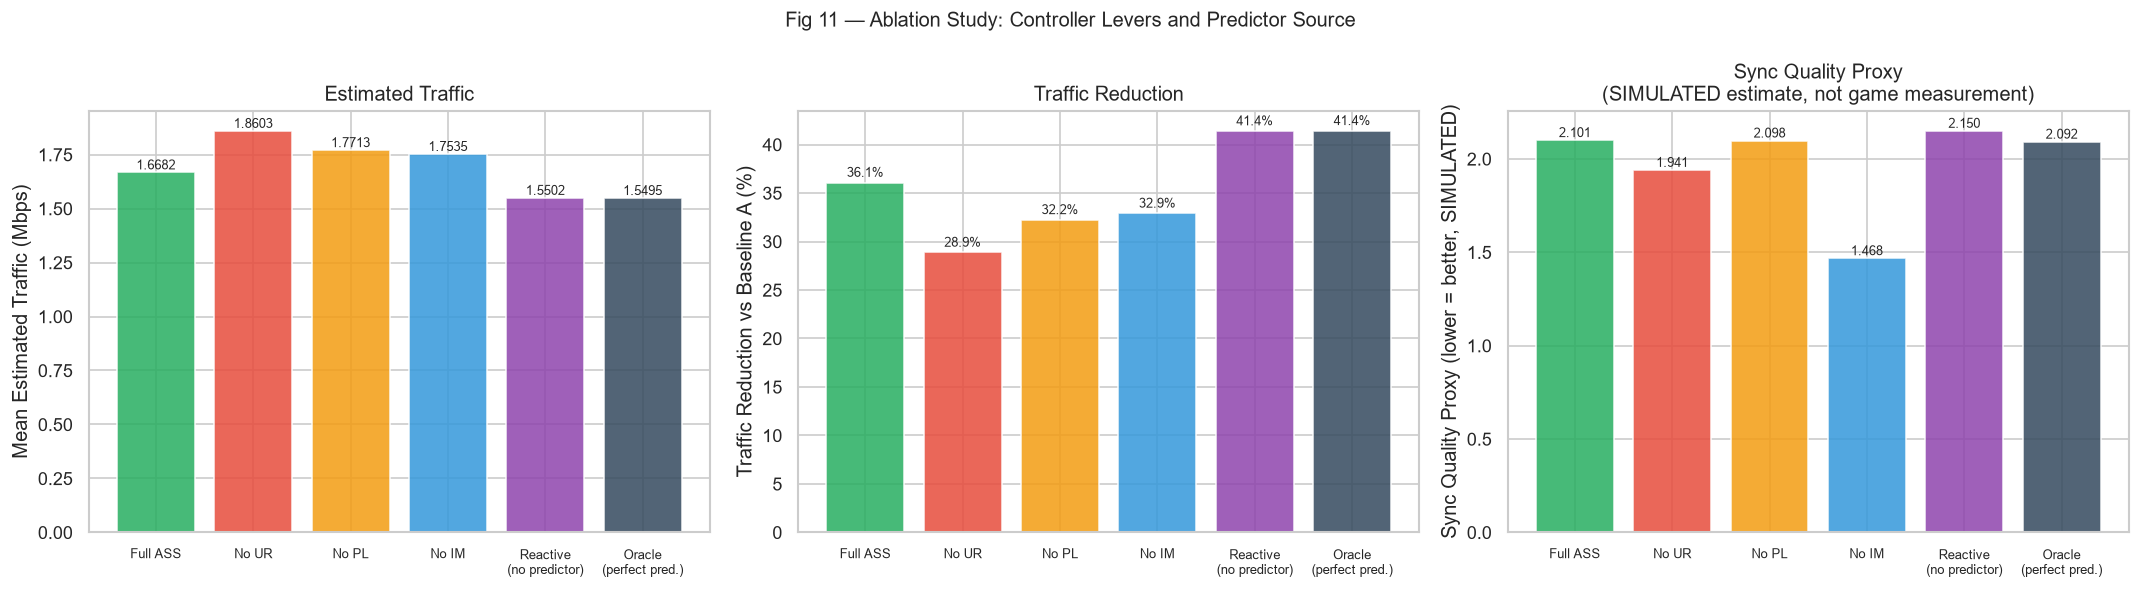

Fig 11 saved.


In [27]:
# Figure: Ablation study
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

abl_colors = ['#27ae60','#e74c3c','#f39c12','#3498db','#8e44ad','#34495e']
abl_labels = ['Full ASS','No UR','No PL','No IM','Reactive\n(no predictor)','Oracle\n(perfect pred.)']
abl_names_ordered = abl_methods

# Traffic
ax = axes[0]
traffic_abl = [abl_summary[abl_summary['method']==m]['mean_traffic_mbps'].values[0]
               for m in abl_names_ordered]
bars = ax.bar(range(len(abl_names_ordered)), traffic_abl, color=abl_colors, alpha=0.85, edgecolor='white')
ax.set_xticks(range(len(abl_names_ordered))); ax.set_xticklabels(abl_labels, fontsize=8)
ax.set_ylabel('Mean Estimated Traffic (Mbps)')
ax.set_title('Estimated Traffic')
for b, v in zip(bars, traffic_abl):
    ax.text(b.get_x()+b.get_width()/2, v+0.0002, f'{v:.4f}', ha='center', va='bottom', fontsize=8)

# Reduction %
ax2 = axes[1]
red_abl = [abl_summary[abl_summary['method']==m]['mean_reduction_pct'].values[0]
           for m in abl_names_ordered]
bars2 = ax2.bar(range(len(abl_names_ordered)), red_abl, color=abl_colors, alpha=0.85, edgecolor='white')
ax2.set_xticks(range(len(abl_names_ordered))); ax2.set_xticklabels(abl_labels, fontsize=8)
ax2.set_ylabel('Traffic Reduction vs Baseline A (%)')
ax2.set_title('Traffic Reduction')
for b, v in zip(bars2, red_abl):
    ax2.text(b.get_x()+b.get_width()/2, v+0.3, f'{v:.1f}%', ha='center', va='bottom', fontsize=8)

# Sync quality proxy
ax3 = axes[2]
sq_abl = [abl_summary[abl_summary['method']==m]['mean_sync_quality'].values[0]
          for m in abl_names_ordered]
bars3 = ax3.bar(range(len(abl_names_ordered)), sq_abl, color=abl_colors, alpha=0.85, edgecolor='white')
ax3.set_xticks(range(len(abl_names_ordered))); ax3.set_xticklabels(abl_labels, fontsize=8)
ax3.set_ylabel('Sync Quality Proxy (lower = better, SIMULATED)')
ax3.set_title('Sync Quality Proxy\n(SIMULATED estimate, not game measurement)')
for b, v in zip(bars3, sq_abl):
    ax3.text(b.get_x()+b.get_width()/2, v+0.001, f'{v:.3f}', ha='center', va='bottom', fontsize=8)

fig.suptitle('Fig 11 — Ablation Study: Controller Levers and Predictor Source', fontsize=12)
plt.tight_layout()
plt.savefig('results/figures/fig11_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 11 saved.')


---
## 14. Statistical Analysis

**Unit of analysis:** Sessions (not individual ticks).  
Ticks within a session are temporally correlated. Using them as independent
observations would violate the i.i.d. assumption of statistical tests.
Each of the 144 test sessions gives one paired observation (same session, two methods),
so every comparison uses 144 paired session-level means.

**Tests applied:**
- Shapiro-Wilk normality test on traffic differences
- Wilcoxon signed-rank test (non-parametric, appropriate when normality is rejected)
- Cohen's d effect size
- 95% bootstrap confidence intervals

The Wilcoxon test is one-sided (H1: ASS uses less traffic). Significance is reported at both α = 0.05 and the
stricter α = 0.001.


In [28]:
# Session-level statistical comparison: ASS Proposed vs each baseline
from scipy.stats import shapiro, wilcoxon

COMPARE_METHODS = [
    ('Baseline_A_StaticFullSync', 'Base-A (Static Full)'),
    ('Baseline_B_FixedRuleALC',   'Base-B (Fixed ALC)'),
    ('Baseline_C_PredictNoAct',   'Base-C (Pred-NoAct)'),
    ('Baseline_D_StaticPlacement','Base-D (Static Plc)'),
    ('ASS_Reactive',              'ASS-Reactive (no predictor)'),
]
boot_rng = np.random.default_rng(SEED)

ass_sessions = sess_red[sess_red['method']=='ASS_Proposed'].set_index(
    ['path','genre','n_clients','repetition'])['mean_traffic_mbps']

print("=== Session-Level Statistical Tests ===\n")
print(f"Number of test sessions: {len(ass_sessions)}")
print("Traffic metric: mean_traffic_mbps per session")
print("Null hypothesis: ASS traffic == Baseline traffic")
print()

stat_rows = []
for baseline_method, baseline_label in COMPARE_METHODS:
    base_sessions = sess_red[sess_red['method']==baseline_method].set_index(
        ['path','genre','n_clients','repetition'])['mean_traffic_mbps']
    
    # Align on common index
    common_idx = ass_sessions.index.intersection(base_sessions.index)
    ass_vals   = ass_sessions.loc[common_idx].values
    base_vals  = base_sessions.loc[common_idx].values
    diffs      = base_vals - ass_vals   # positive = ASS uses less
    
    # Shapiro-Wilk normality test
    sw_stat, sw_p = shapiro(diffs[:min(len(diffs),5000)])
    normal = sw_p >= 0.05
    
    # Wilcoxon signed-rank (appropriate for non-normal paired data)
    if len(diffs) > 0 and not np.allclose(diffs, 0):
        wx_stat, wx_p = wilcoxon(ass_vals, base_vals, alternative='less')
    else:
        wx_stat, wx_p = np.nan, np.nan
    
    # Cohen's d
    cohen_d = np.mean(diffs) / (np.std(diffs) + 1e-12)
    
    # 95% bootstrap CI on mean difference
    boot_means = [np.mean(boot_rng.choice(diffs, len(diffs), replace=True))
                  for _ in range(2000)]
    ci_lo, ci_hi = np.percentile(boot_means, [2.5, 97.5])
    
    stat_rows.append({
        'comparison':    f'ASS vs {baseline_label}',
        'n_sessions':    len(common_idx),
        'mean_diff':     round(np.mean(diffs), 5),
        'ci_95_lo':      round(ci_lo, 5),
        'ci_95_hi':      round(ci_hi, 5),
        'sw_p':          round(sw_p, 4),
        'normal':        normal,
        'wilcoxon_p':    float(wx_p),   # unrounded: tiny p-values must not collapse to 0
        'sig_p005':      wx_p < 0.05 if not np.isnan(wx_p) else False,
        'sig_p001':      wx_p < 0.001 if not np.isnan(wx_p) else False,
        'cohens_d':      round(cohen_d, 3),
        'effect_size':   'Large' if abs(cohen_d)>0.8 else ('Medium' if abs(cohen_d)>0.5 else 'Small'),
    })
    
    print(f"{baseline_label}:")
    print(f"  Shapiro-Wilk p={sw_p:.4f} → {'normal' if normal else 'non-normal'}")
    print(f"  Wilcoxon W={wx_stat:.1f}, p={wx_p:.2e} → {'significant at 0.001' if wx_p<0.001 else ('significant at 0.05 only' if wx_p<0.05 else 'NOT significant')}")
    print(f"  Mean diff: {np.mean(diffs):.5f} Mbps (95% CI: [{ci_lo:.5f}, {ci_hi:.5f}])")
    print(f"  Cohen's d = {cohen_d:.3f} ({stat_rows[-1]['effect_size']} effect)")
    print()

stat_df = pd.DataFrame(stat_rows)
display(stat_df)
stat_df.to_csv('results/tables/statistical_tests.csv', index=False)
print("Saved to results/tables/statistical_tests.csv")
print()
print("INTERPRETATION NOTE: Statistical significance reflects that ASS traffic differs")
print("from baseline traffic in the simulation. It does NOT imply real-world benefit.")
print("Effect size (Cohen's d) is more informative than p-value alone.")


=== Session-Level Statistical Tests ===

Number of test sessions: 144
Traffic metric: mean_traffic_mbps per session
Null hypothesis: ASS traffic == Baseline traffic

Base-A (Static Full):
  Shapiro-Wilk p=0.0000 → non-normal
  Wilcoxon W=0.0, p=1.33e-18 → significant at 0.001
  Mean diff: 1.00769 Mbps (95% CI: [0.74662, 1.28486])
  Cohen's d = 0.601 (Medium effect)

Base-B (Fixed ALC):
  Shapiro-Wilk p=0.0056 → non-normal
  Wilcoxon W=6320.0, p=9.86e-01 → NOT significant
  Mean diff: -0.18246 Mbps (95% CI: [-0.41027, 0.04897])
  Cohen's d = -0.131 (Small effect)

Base-C (Pred-NoAct):
  Shapiro-Wilk p=0.0000 → non-normal
  Wilcoxon W=763.0, p=4.12e-10 → significant at 0.001
  Mean diff: 0.23233 Mbps (95% CI: [0.16562, 0.30859])
  Cohen's d = 0.542 (Medium effect)



Base-D (Static Plc):
  Shapiro-Wilk p=0.0000 → non-normal
  Wilcoxon W=4292.0, p=3.21e-02 → significant at 0.05 only
  Mean diff: 0.50083 Mbps (95% CI: [0.27144, 0.75840])
  Cohen's d = 0.336 (Small effect)



ASS-Reactive (no predictor):
  Shapiro-Wilk p=0.0000 → non-normal
  Wilcoxon W=6975.0, p=1.00e+00 → NOT significant
  Mean diff: -0.11801 Mbps (95% CI: [-0.21652, -0.02142])
  Cohen's d = -0.197 (Small effect)



,comparison,n_sessions,mean_diff,ci_95_lo,ci_95_hi,sw_p,normal,wilcoxon_p,sig_p005,sig_p001,cohens_d,effect_size
0,ASS vs Base-A (Static Full),144,1.00769,0.74662,1.28486,0.0000,False,1.332570e-18,True,True,0.601,Medium
1,ASS vs Base-B (Fixed ALC),144,-0.18246,-0.41027,0.04897,0.0056,False,9.858728e-01,False,False,-0.131,Small
2,ASS vs Base-C (Pred-NoAct),144,0.23233,0.16562,0.30859,0.0000,False,4.123698e-10,True,True,0.542,Medium
3,ASS vs Base-D (Static Plc),144,0.50083,0.27144,0.75840,0.0000,False,3.210532e-02,True,False,0.336,Small
4,ASS vs ASS-Reactive (no predictor),144,-0.11801,-0.21652,-0.02142,0.0000,False,9.997674e-01,False,False,-0.197,Small


Saved to results/tables/statistical_tests.csv

INTERPRETATION NOTE: Statistical significance reflects that ASS traffic differs
from baseline traffic in the simulation. It does NOT imply real-world benefit.
Effect size (Cohen's d) is more informative than p-value alone.


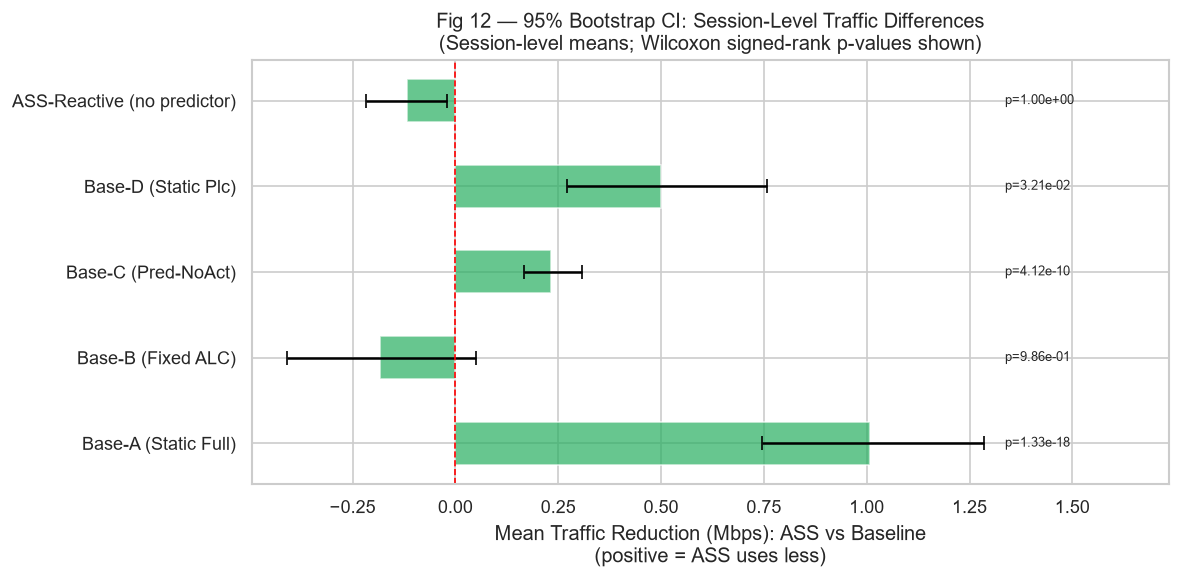

Fig 12 saved.


In [29]:
# Figure: Confidence interval plot
fig, ax = plt.subplots(figsize=(10, 5))

comparisons = [r['comparison'].replace('ASS vs ','') for r in stat_rows]
means  = [r['mean_diff'] for r in stat_rows]
ci_los = [r['ci_95_lo'] for r in stat_rows]
ci_his = [r['ci_95_hi'] for r in stat_rows]
p_vals = [r['wilcoxon_p'] for r in stat_rows]

y_pos = range(len(comparisons))
ax.barh(y_pos, means, color=['#27ae60']*len(means), alpha=0.7, height=0.5)
ax.errorbar(means, y_pos, xerr=[[m-lo for m,lo in zip(means,ci_los)],
                                 [hi-m for m,hi in zip(means,ci_his)]],
            fmt='none', color='black', capsize=4, linewidth=1.5)
ax.axvline(0, color='red', linestyle='--', linewidth=1)
ax.set_yticks(list(y_pos)); ax.set_yticklabels(comparisons)
ax.set_xlabel('Mean Traffic Reduction (Mbps): ASS vs Baseline\n(positive = ASS uses less)')
ax.set_title('Fig 12 — 95% Bootstrap CI: Session-Level Traffic Differences\n(Session-level means; Wilcoxon signed-rank p-values shown)')
for i, (m, p) in enumerate(zip(means, p_vals)):
    sig_str = f"p={p:.2e}" if not np.isnan(p) else 'N/A'
    ax.text(max(ci_his)*1.04, i, sig_str, va='center', fontsize=8)
ax.set_xlim(right=max(ci_his)*1.35)
plt.tight_layout()
plt.savefig('results/figures/fig12_confidence_intervals.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 12 saved.')


---
## 15. Comparison with Existing Research

> **Important disclaimer:** Direct numerical comparison with published papers is not possible
> because: (1) our dataset is synthetic, (2) the published papers use real game engines and
> real network paths, (3) metric definitions differ.
> The comparison below is methodological/qualitative only.


In [30]:
# Qualitative comparison table
comparison_rows = [
    {
        'Paper': 'Monaco et al. (CLAAP, 2025)',
        'Their setting': 'Google Stadia / Dirt 4, single LAN testbed, real traffic',
        'Our setting': 'Synthetic simulation, 4 paths, 2 genres',
        'Comparable': 'RBFNN + drift detection architecture, inference latency',
        'Not comparable': 'Absolute FPS, real RTT, actual player experience',
        'Our result': f"Test NRMSE RTT={test_metrics['rtt']['nrmse']:.3f}, NRMSE BW={test_metrics['bw']['nrmse']:.3f}",
        'Their result': 'NRMSE not directly reported; ~21% error reduction vs offline',
    },
    {
        'Paper': 'Lee & Chang (ALC, 2018)',
        'Their setting': '12 human participants, Unreal Engine 4, 250ms injected delay',
        'Our setting': 'Simulated fixed throttle (UR=0.75)',
        'Comparable': 'Concept of moderate bandwidth throttling',
        'Not comparable': 'SBC rate, perceptual fairness, hit registration',
        'Our result': f"Base-B fixed throttle: {overall[overall['method']=='Baseline_B_FixedRuleALC']['mean_reduction_pct'].values[0]:.1f}% traffic reduction vs Base-A",
        'Their result': '94.1% SBC reduction (not applicable here)',
    },
    {
        'Paper': 'García Fernández de Castro et al. (2025)',
        'Their setting': 'Synthetic edge-placement simulation',
        'Our setting': 'Synthetic fixed static placement approximation',
        'Comparable': 'Both are simulations of infrastructure-level savings',
        'Not comparable': 'Actual edge placement geography, routing costs',
        'Our result': f"Base-D traffic ≈ {overall[overall['method']=='Baseline_D_StaticPlacement']['mean_traffic_mbps'].values[0]:.4f} Mbps",
        'Their result': '67.5% average latency reduction (not traffic reduction)',
    },
]
df_comp = pd.DataFrame(comparison_rows)
display(df_comp[['Paper','Comparable','Not comparable','Our result','Their result']].T)
df_comp.to_csv('results/tables/literature_comparison.csv', index=False)
print("Saved to results/tables/literature_comparison.csv")


,0,1,2
Paper,"Monaco et al. (CLAAP, 2025)","Lee & Chang (ALC, 2018)",García Fernández de Castro et al. (2025)
Comparable,"RBFNN + drift detection architecture, inferenc...",Concept of moderate bandwidth throttling,Both are simulations of infrastructure-level s...
Not comparable,"Absolute FPS, real RTT, actual player experience","SBC rate, perceptual fairness, hit registration","Actual edge placement geography, routing costs"
Our result,"Test NRMSE RTT=0.096, NRMSE BW=0.056",Base-B fixed throttle: 44.3% traffic reduction...,Base-D traffic ≈ 2.1691 Mbps
Their result,NRMSE not directly reported; ~21% error reduct...,94.1% SBC reduction (not applicable here),67.5% average latency reduction (not traffic r...


Saved to results/tables/literature_comparison.csv


---
## 16. Results and Discussion

All numbers are from the held-out test sessions (144 sessions, 82,800 rows) of the synthetic dataset.

### 16.1 Does the predictor forecast network conditions accurately?

Only partly. On the test set the RBF predictor reaches RTT MAE 32.3 ms (NRMSE 0.096), bandwidth MAE 5.9 Mbps
(NRMSE 0.056) and future-severity accuracy 59.4% (macro-F1 0.446). The Mild class is almost never predicted
(validation recall 0.04), and accuracy falls from ≈0.86 on LAN to ≈0.35 on Mobile 4G.

The naive baselines in Section 7.2 (Fig 13) are an important check: simply assuming *the next 5 ticks look like
the current tick* gives **better** bandwidth MAE (4.71 vs 5.93 Mbps), **better** severity accuracy and macro-F1
(0.643 / 0.577 vs 0.594 / 0.446) and similar RTT error (MAE 31.1 vs 32.3 ms; RMSE 48.0 vs 46.1 ms). The RBF model
therefore does **not** yet beat persistence. Two reasons are visible in the design:
(1) the input features are 20-tick window statistics ending at *t−1* and exclude the current measurement, and
(2) congestion spikes in the generator are random (≈2% per tick), so they are inherently unpredictable 5 ticks ahead.

### 16.2 Does acting on predictions improve on static policies?

Against static full synchronisation, yes: ASS cuts estimated traffic by **36.1%** relative to Base-A
(Wilcoxon p = 1.3×10⁻¹⁸, Cohen's d = 0.60) and uses less traffic than Base-C (binary gate, p = 4.1×10⁻¹⁰, d = 0.54)
and Base-D (static placement, p = 0.032 — significant at α = 0.05 but not at 0.001, d = 0.34).

Against the **fixed-rule throttle (Base-B), no**. Base-B uses *less* traffic (1.486 vs 1.668 Mbps; difference not
significant, p = 0.99) **and** has a better sync-quality proxy (1.525 vs 2.101, lower is better). In this simulation
Base-B dominates ASS on both axes. The cause is the policy table: at predicted severity 3 ASS drops to 15 Hz and
40% interest radius, which saves traffic on bad ticks but heavily penalises state freshness, while misclassified
"None" ticks keep full traffic. A fixed moderate throttle avoids both extremes.

*Where the savings come from.* Per path, ASS saves 0.0% traffic on LAN and 4.3% on Home Broadband but 85.1% on
Mobile 4G and 81.5% on Cross-Region Cloud (Base-B saves ≈44% everywhere); across client counts the saving stays
at 35–37%. The predictor therefore acts almost like a per-path switch — full sync on good paths, heavy
throttling on poor ones — rather than reacting to short-term changes within a session.

### 16.3 Which components contribute most? (ablations)

*Lever ablations.* Removing update-rate scaling raises traffic the most (+11.5% vs full ASS), then compression
(+6.2%), then interest management (+5.1%). Interest management is the most expensive lever for quality: without it
the proxy improves from 2.10 to **1.47** for only 5% more traffic, making `ASS_no_IM` the best quality/traffic
trade-off among the ASS variants.

*Predictor ablations.* Driving the controller with the **current** severity (`ASS_Reactive`, no predictor) uses
**7.1% less** traffic than RBF-driven ASS (1.550 vs 1.668 Mbps; 95% CI of the difference −0.217 to −0.021 Mbps),
with a slightly worse proxy (2.150 vs 2.101). A **perfect** predictor (`ASS_Oracle`) gives almost the same traffic
as Reactive (1.549 Mbps) with a proxy of 2.092. So, in this simulation, forecasting contributes little: perfect
foresight improves quality by only ≈0.06 over reacting to the present, and the current RBF predictor loses traffic
efficiency because its severity errors are biased toward class 0 (full synchronisation).

### 16.4 Trade-off between bandwidth and synchronisation quality

Every lever that saves traffic worsens the simulated quality proxy, as expected: lower update rate makes state
older and a smaller interest radius drops entities. The ablations show the trade-off is not uniform — update-rate
scaling gives the most traffic saving per unit of quality lost, interest management the least.

### 16.5 Strengths

- Closed prediction→action loop with independently switchable levers, so each component can be measured.
- Leakage-safe pipeline: future targets never used as inputs, session-based split, scaler fitted on train only.
- Session-level paired statistics with effect sizes and bootstrap CIs rather than tick-level tests.
- Fully reproducible: the generator re-creates the dataset byte-for-byte from seed 42.

### 16.6 Limitations

1. **Synthetic dataset** — AR(1) RTT/bandwidth, random spikes and burst loss approximate, but are not, real traffic.
2. **Predictor does not beat persistence** — see 16.1.
3. **Drift detection** — the BOCPD approximation detected 0 changepoints and retraining is not implemented.
4. **Modelled metrics** — traffic is estimated from a formula and quality is a simulated proxy; no packet capture,
   FPS, reconciliation error or player study.
5. **Fixed policy table** — UR/CL/IR levels were set by hand, not tuned or learned.
6. **Baselines are approximations** inspired by the cited papers, not faithful re-implementations.
7. **Inference timing** (≈19 µs per row on the machine used) covers one batched `predict()` call only, and is
   hardware-dependent.

### 16.7 Does this address the research gap?

Partially. The gap asks for a system that forecasts latency and bandwidth and uses the forecast to adapt state
synchronisation, validated across more than one genre and more than one real network path. This work builds and
evaluates that closed loop across two genres and four network profiles, and isolates every component with
ablations (Objectives 1–4). However, (a) the paths are simulated rather than real, (b) the forecast does not yet
outperform persistence, and (c) the adaptive controller does not beat a well-chosen fixed throttle. The results
therefore show the loop is **feasible and measurable**, but do not yet show that **prediction-driven** adaptation
is better than simpler reactive or fixed policies.


---
## 17. Conclusion and Future Work

### 17.1 Main Findings

1. The RBF predictor forecasts RTT, bandwidth and severity 5 ticks ahead with test NRMSE 0.096 (RTT) and 0.056
   (bandwidth) and severity accuracy 59.4%, but it does **not** outperform a persistence (last-value) baseline.
2. The ASS controller reduces estimated synchronisation traffic by 36.1% relative to static full sync, and
   significantly outperforms Base-A and Base-C (p < 0.001, medium effects) and Base-D (p = 0.032, small effect).
3. The fixed-rule throttle (Base-B) uses less traffic than ASS (not significant) **and** has better simulated
   sync quality, so ASS is not the best policy in this simulation.
4. Update-rate scaling is the most effective lever (+11.5% traffic when removed); interest management costs the
   most quality.
5. Replacing the predictor with the current severity lowers traffic by 7.1%, and a perfect predictor gives almost
   the same traffic as reacting to the present — the value of forecasting is small under these simulated dynamics.
6. The drift monitor detected no changepoints on the validation stream; retraining remains unimplemented.

### 17.2 Contributions

- Reproducible, leakage-safe pipeline: deterministic generator, future targets, session-based splitting.
- A trained RBF predictor evaluated honestly against naive forecasting baselines.
- Vectorised evaluation of 10 methods on 82,800 test rows in seconds.
- Two ablation families (remove a lever, replace the predictor) that isolate every component.
- Session-level paired statistics with effect sizes and bootstrap confidence intervals.

### 17.3 Future Work

1. **Better predictor** — add the current measurement and longer histories as features, use class weighting for
   the Mild class, and require the model to beat persistence before it drives the controller.
2. **Tune the policy table** — optimise UR/CL/IR per severity (or learn the policy) against a combined
   traffic–quality objective; the ablations suggest milder interest-radius cuts.
3. **Real traces** — validate on captured multiplayer traffic and real network paths.
4. **Full BOCPD with retraining** — implement Adams & MacKay (2007) and retrain on detected drift.
5. **Game-engine integration** — measure real throughput, FPS, reconciliation error and player experience.
6. **More genres and longer horizons** (H = 10, 20, 50 ticks).


---
## References

1. Adams, R. P., & MacKay, D. J. C. (2007). *Bayesian online changepoint detection.* arXiv:0710.3742. https://doi.org/10.48550/arXiv.0710.3742
2. García Fernández de Castro, E. J., García Puche, E. J., & Jabba Molinares, D. (2025). Dynamic low-latency load balancing model to improve quality of experience in a hybrid fog and edge architecture for massively multiplayer online (MMO) games. *Applied Sciences, 15*(12), 6379. https://doi.org/10.3390/app15126379
3. Lee, S. W. K., & Chang, R. K. C. (2018). Enhancing the experience of multiplayer shooter games via advanced lag compensation. In *Proceedings of the 9th ACM Multimedia Systems Conference (MMSys '18)* (pp. 284–293). ACM.
4. Monaco, D., Sacco, A., Spina, D., Strada, F., Bottino, A., Cerquitelli, T., & Marchetto, G. (2025). Real-time latency prediction for cloud gaming applications. *Computer Networks, 264*, 111235. https://doi.org/10.1016/j.comnet.2025.111235


In [31]:
print("=== NOTEBOOK EXECUTION COMPLETE ===")
print("All figures saved to results/figures/")
print("All tables saved to results/tables/")


=== NOTEBOOK EXECUTION COMPLETE ===
All figures saved to results/figures/
All tables saved to results/tables/
